In [2]:
import pandas as pd
import os
import glob
import datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

BASE_PATH = r"/home/ashutosh-tiwari/Desktop/CausalProject" 

PEAK_HOURS = [8, 9, 10, 11, 17, 18, 19, 20]

In [3]:
def load_pollution_data(peak_hours, intervention_date, window_days, stations_list, years_to_load, base_path=BASE_PATH):
    """
    Loads, cleans, and filters pollution data for a specific list of stations 
    around a given intervention date.
    
    Parameters:
    -----------
    peak_hours : list
        List of integers representing hours to keep (e.g., [8, 9, 10]).
    intervention_date : datetime.datetime
        The date of the metro opening/intervention.
    window_days : int
        Number of days before and after the intervention to include.
    stations_list : list
        List of strings containing station names to search for.
    base_path : str
        The root directory containing station data folders.
        
    Returns:
    --------
    pd.DataFrame
        Combined dataframe of all loaded stations. Returns None if no data found.
    """
    
    start_date = intervention_date - datetime.timedelta(days=window_days)
    end_date = intervention_date + datetime.timedelta(days=window_days)
    
    print(f"\n{'='*100}")
    print(f"PROCESSING DATA")
    print(f"Intervention Date: {intervention_date.date()}")
    print(f"Window: {window_days} days (Period: {start_date.date()} to {end_date.date()})")
    print(f"{'='*100}")
    print(f"{'STATION NAME':<25} | {'ROWS':<8} | {'MISSING PM2.5 (N/%)':<22} | {'MISSING PM10 (N/%)':<22}")
    print(f"{'='*100}")

    all_data = []

    for station in stations_list:
        for year in years_to_load:
            search_pattern = os.path.join(base_path, f"*{station}*", f"*{year}*.csv")
            files = glob.glob(search_pattern)
            
            if not files:
                search_pattern_loose = os.path.join(base_path, "**", f"*{station}*{year}*.csv")
                files = glob.glob(search_pattern_loose, recursive=True)

            if not files:
                print(f"{station:<25} | {'NO FILE':<8} | {'-':<22} | {'-':<22}")
                continue
            
            file_path = files[0]
            
            try:
                df = pd.read_csv(file_path)
                
                df.columns = [c.strip() for c in df.columns]
                col_map = {}
                for col in df.columns:
                    if 'Timestamp' in col: col_map[col] = 'TimeStamp'
                    elif 'PM2.5' in col: col_map[col] = 'PM2.5'
                    elif 'PM10' in col: col_map[col] = 'PM10'
                
                df = df.rename(columns=col_map)
                
                if 'TimeStamp' not in df.columns or 'PM2.5' not in df.columns or 'PM10' not in df.columns:
                    print(f"{station:<25} | {'BAD COLS':<8} | {'-':<22} | {'-':<22}")
                    continue

                df['TimeStamp'] = pd.to_datetime(df['TimeStamp'], errors='coerce')
                
                mask_date = (df['TimeStamp'] >= start_date) & (df['TimeStamp'] <= end_date)
                df_window = df.loc[mask_date].copy()

                df_window['Hour'] = df_window['TimeStamp'].dt.hour
                df_peak = df_window[df_window['Hour'].isin(peak_hours)].copy()
                
                df_peak['StationName'] = station
                
                final_df = df_peak[['TimeStamp', 'PM2.5', 'PM10', 'StationName']]
                
                total_rows = len(final_df)
                missing_pm25 = final_df['PM2.5'].isna().sum()
                missing_pm10 = final_df['PM10'].isna().sum()
                
                if total_rows > 0:
                    pm25_pct = (missing_pm25 / total_rows) * 100
                    pm10_pct = (missing_pm10 / total_rows) * 100
                else:
                    pm25_pct = 0
                    pm10_pct = 0
                
                pm25_str = f"{missing_pm25} ({pm25_pct:.1f}%)"
                pm10_str = f"{missing_pm10} ({pm10_pct:.1f}%)"
                
                print(f"{station:<25} | {total_rows:<8} | {pm25_str:<22} | {pm10_str:<22}")
                
                all_data.append(final_df)
                
            except Exception as e:
                print(f"Error processing {station}: {e}")

    print(f"{'='*100}")

    if all_data:
        combined_df = pd.concat(all_data, ignore_index=True)
        return combined_df
    else:
        return None

In [4]:
def run_and_plot_aggregated_rdd(df, pollutant_col, intervention_date):
    """
    Aggregates data by timestamp, runs RDD, and plots the results.
    """
    df_agg = df.groupby('TimeStamp')[pollutant_col].mean().reset_index()

    df_agg['days_relative'] = (df_agg['TimeStamp'] - intervention_date).dt.total_seconds() / (24 * 3600)
    # df_agg['days_sq'] = df_agg['days_relative'] ** 2

    df_agg['treatment'] = (df_agg['days_relative'] >= 0).astype(int)

    # Formula: Outcome = Intercept + Slope*Time + Jump*Treatment + ChangeInSlope*(Time*Treatment)
    # formula = f"{pollutant_col} ~ (days_relative + days_sq) * treatment"
    formula = f"{pollutant_col} ~ (days_relative) * treatment"
    
    # Fit OLS model with robust standard errors
    model = smf.ols(formula=formula, data=df_agg).fit()
    
    print(f"\n{'='*20} RDD RESULTS: {pollutant_col} {'='*20}")
    print(model.summary())

    plt.figure(figsize=(12, 6))

    sns.scatterplot(
        x='days_relative', 
        y=pollutant_col, 
        data=df_agg, 
        hue='treatment', 
        palette={0: 'navy', 1: 'darkred'}, 
        alpha=0.5, 
        s=30,
        legend=False
    )

    # if(pollutant_col == 'PM25'):
    #     df_agg.to_csv("PM25_RDD_Predictions.csv", index=False)
    # else:
    #     df_agg.to_csv("PM10_RDD_Predictions.csv", index=False)
    

    df_agg['predicted'] = model.predict(df_agg)
    sns.lineplot(
        x='days_relative', 
        y='predicted', 
        data=df_agg[df_agg['treatment'] == 0], 
        color='navy', 
        linewidth=2.5, 
        label='Pre-Intervention Trend'
    )
    
    sns.lineplot(
        x='days_relative', 
        y='predicted', 
        data=df_agg[df_agg['treatment'] == 1], 
        color='darkred', 
        linewidth=2.5, 
        label='Post-Intervention Trend'
    )

    plt.axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Metro Opening')
    plt.title(f'RDD Analysis: Impact of Pink Line Opening on {pollutant_col} levels', fontsize=14)
    plt.xlabel('Days Relative to Opening', fontsize=12)
    plt.ylabel(f'Average {pollutant_col} Concentration (µg/m³)', fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


PROCESSING DATA
Intervention Date: 2018-03-14
Window: 15 days (Period: 2018-02-27 to 2018-03-29)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Punjabi Bagh              | 240      | 8 (3.3%)               | 12 (5.0%)             
Wazirpur                  | 240      | 12 (5.0%)              | 11 (4.6%)             
Ashok Vihar               | 240      | 8 (3.3%)               | 8 (3.3%)              
JahangirPuri              | 240      | 6 (2.5%)               | 17 (7.1%)             
Burari Crossing           | 240      | 10 (4.2%)              | 69 (28.7%)            
Shadipur                  | 240      | 15 (6.2%)              | 240 (100.0%)          
R K Puram                 | 240      | 6 (2.5%)               | 6 (2.5%)              
Pusa                      | 240      | 1 (0.4%)               | 3 (1.2%)              
North Campus              | 240      | 12 (5.0%)              | 0 (0.0%)              

SUCCESS: Data saved to Stage1_P

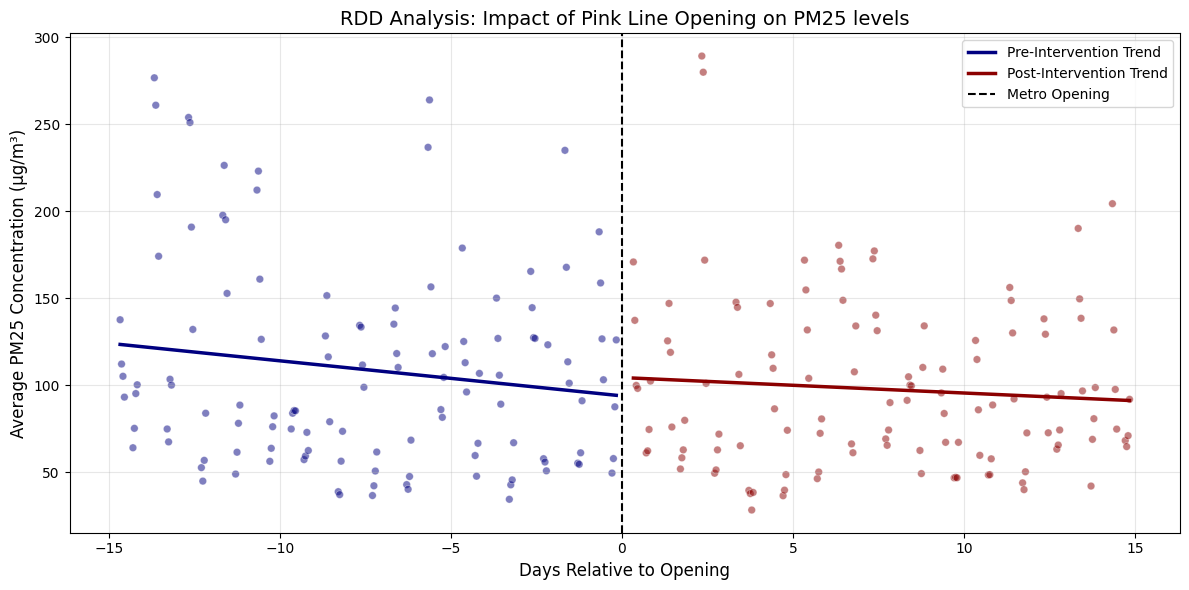


==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.028
Method:                 Least Squares   F-statistic:                     3.262
Date:                Thu, 27 Nov 2025   Prob (F-statistic):             0.0222
Time:                        09:09:29   Log-Likelihood:                -1404.5
No. Observations:                 240   AIC:                             2817.
Df Residuals:                     236   BIC:                             2831.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

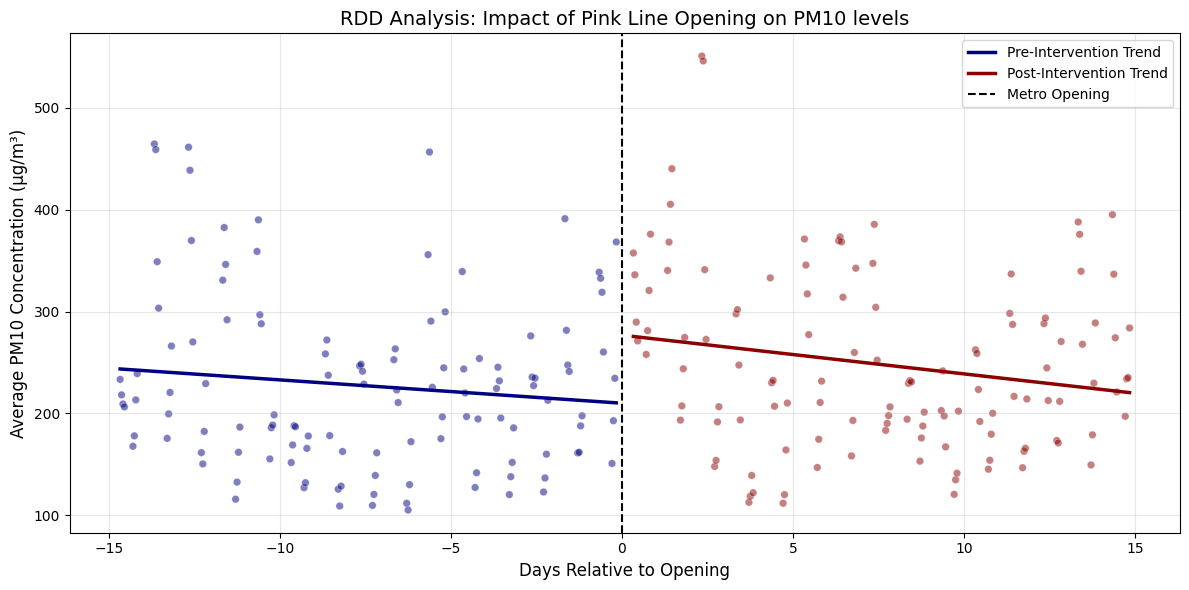

In [5]:
#Stage 1 Opening

stage_1_stations = [
    "Punjabi Bagh", 
    "Wazirpur", 
    "Ashok Vihar", 
    "JahangirPuri", 
    "Burari Crossing", 
    "Shadipur", 
    "R K Puram", 
    "Pusa",
    "North Campus"
]

INTERVENTION_DATE = datetime.datetime(2018, 3, 14) 
WINDOW_DAYS = 15

stage1_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE,
    window_days=WINDOW_DAYS,
    stations_list=stage_1_stations,
    years_to_load=[2018],
    base_path=BASE_PATH
)

if stage1_df is not None:
    output_filename = "Stage1_PeakHours_Pollution_Data.csv"
    # stage1_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage1_df.head())
    print("\nDataframe Info:")
    print(stage1_df.info())
    df_pm25 = stage1_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10 = stage1_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    df_pm25 = df_pm25.rename(columns={'PM2.5': 'PM25'})
    df_pm10 = df_pm10.rename(columns={'PM10': 'PM10'})

    run_and_plot_aggregated_rdd(df_pm25, 'PM25', INTERVENTION_DATE)
    run_and_plot_aggregated_rdd(df_pm10, 'PM10', INTERVENTION_DATE)
else:
    print("\nFAILURE: No data was loaded.")


PROCESSING DATA
Intervention Date: 2018-03-29
Window: 15 days (Period: 2018-03-14 to 2018-04-13)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Punjabi Bagh              | 240      | 13 (5.4%)              | 17 (7.1%)             
Wazirpur                  | 240      | 16 (6.7%)              | 18 (7.5%)             
Ashok Vihar               | 240      | 24 (10.0%)             | 24 (10.0%)            
JahangirPuri              | 240      | 12 (5.0%)              | 22 (9.2%)             
Burari Crossing           | 240      | 10 (4.2%)              | 182 (75.8%)           
Shadipur                  | 240      | 9 (3.8%)               | 240 (100.0%)          
R K Puram                 | 240      | 30 (12.5%)             | 27 (11.2%)            
Pusa                      | 240      | 8 (3.3%)               | 15 (6.2%)             
North Campus              | 240      | 2 (0.8%)               | 0 (0.0%)              

SUCCESS: Data saved to Stage1_P

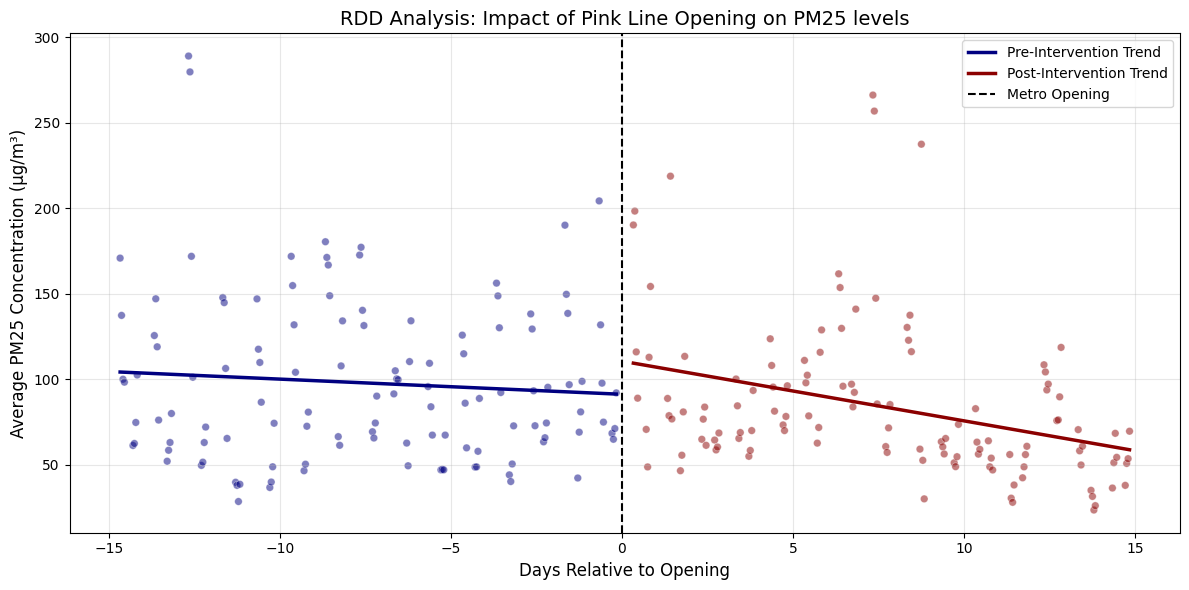


==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.078
Method:                 Least Squares   F-statistic:                     7.751
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           5.86e-05
Time:                        09:09:30   Log-Likelihood:                -1404.7
No. Observations:                 240   AIC:                             2817.
Df Residuals:                     236   BIC:                             2831.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

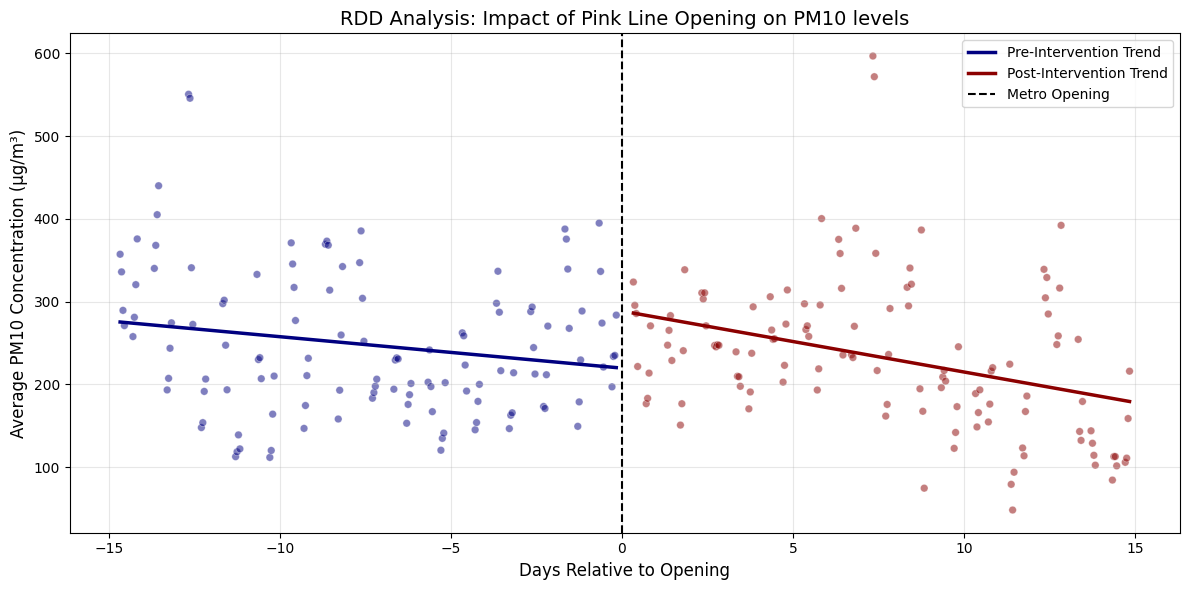

In [6]:
#Stage 1 Opening

stage_1_stations = [
    "Punjabi Bagh", 
    "Wazirpur", 
    "Ashok Vihar", 
    "JahangirPuri", 
    "Burari Crossing", 
    "Shadipur", 
    "R K Puram", 
    "Pusa",
    "North Campus"
]

INTERVENTION_DATE = datetime.datetime(2018, 3, 29) 
WINDOW_DAYS = 15

stage1_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE,
    window_days=WINDOW_DAYS,
    stations_list=stage_1_stations,
    years_to_load=[2018],
    base_path=BASE_PATH
)

if stage1_df is not None:
    output_filename = "Stage1_PeakHours_Pollution_Data.csv"
    # stage1_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage1_df.head())
    print("\nDataframe Info:")
    print(stage1_df.info())
    df_pm25 = stage1_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10 = stage1_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    df_pm25 = df_pm25.rename(columns={'PM2.5': 'PM25'})
    df_pm10 = df_pm10.rename(columns={'PM10': 'PM10'})

    run_and_plot_aggregated_rdd(df_pm25, 'PM25', INTERVENTION_DATE)
    run_and_plot_aggregated_rdd(df_pm10, 'PM10', INTERVENTION_DATE)
else:
    print("\nFAILURE: No data was loaded.")

Loading Treatment Data (6 stations)...

PROCESSING DATA
Intervention Date: 2018-03-14
Window: 15 days (Period: 2018-02-27 to 2018-03-29)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Punjabi Bagh              | 240      | 8 (3.3%)               | 12 (5.0%)             
Wazirpur                  | 240      | 12 (5.0%)              | 11 (4.6%)             
Ashok Vihar               | 240      | 8 (3.3%)               | 8 (3.3%)              
JahangirPuri              | 240      | 6 (2.5%)               | 17 (7.1%)             
Shadipur                  | 240      | 15 (6.2%)              | 240 (100.0%)          
R K Puram                 | 240      | 6 (2.5%)               | 6 (2.5%)              
Loading Control Data (5 stations)...

PROCESSING DATA
Intervention Date: 2018-03-14
Window: 15 days (Period: 2018-02-27 to 2018-03-29)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Anand Vihar               | 240 

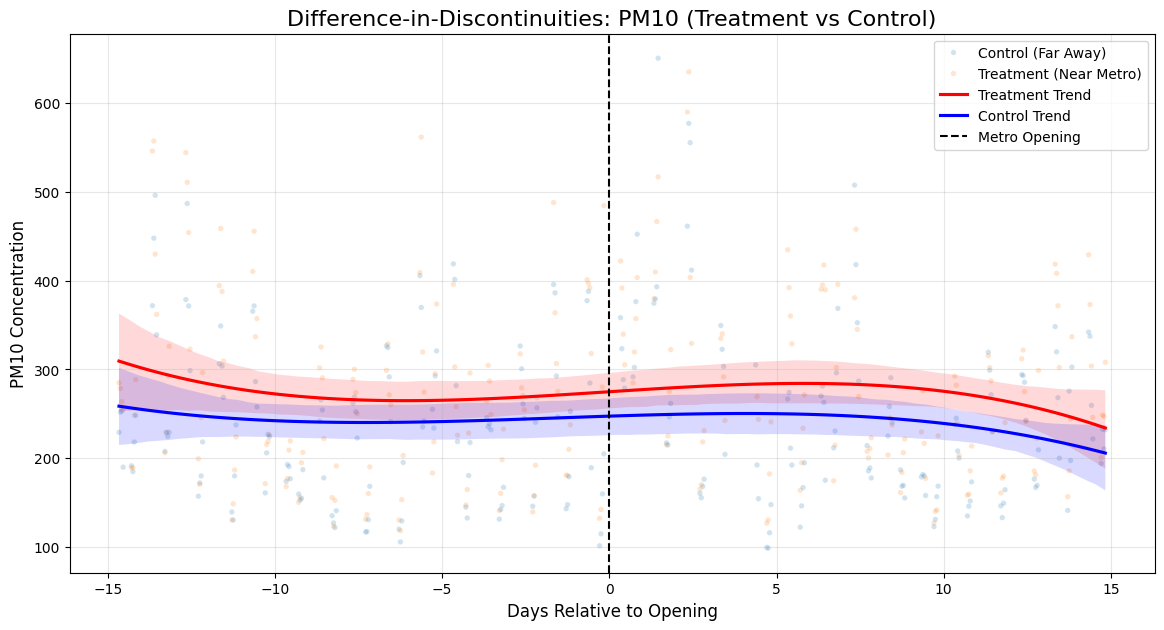

Loading Treatment Data (6 stations)...

PROCESSING DATA
Intervention Date: 2018-03-14
Window: 15 days (Period: 2018-02-27 to 2018-03-29)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Punjabi Bagh              | 240      | 8 (3.3%)               | 12 (5.0%)             
Wazirpur                  | 240      | 12 (5.0%)              | 11 (4.6%)             
Ashok Vihar               | 240      | 8 (3.3%)               | 8 (3.3%)              
JahangirPuri              | 240      | 6 (2.5%)               | 17 (7.1%)             
Shadipur                  | 240      | 15 (6.2%)              | 240 (100.0%)          
R K Puram                 | 240      | 6 (2.5%)               | 6 (2.5%)              
Loading Control Data (5 stations)...

PROCESSING DATA
Intervention Date: 2018-03-14
Window: 15 days (Period: 2018-02-27 to 2018-03-29)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Anand Vihar               | 240 

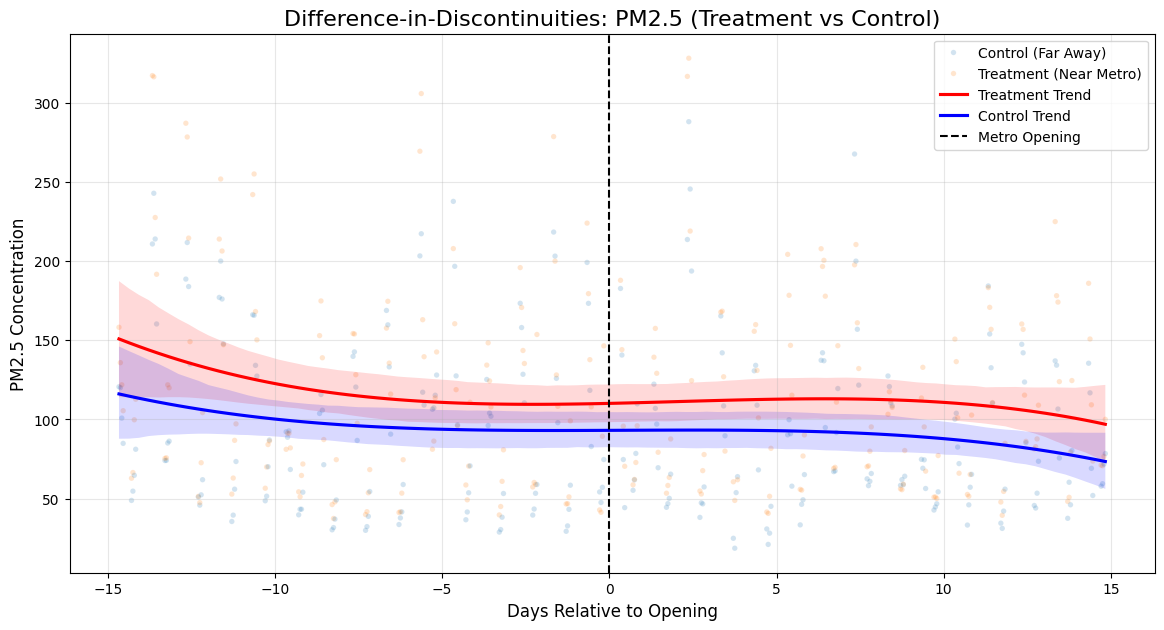

In [7]:
def compare_treatment_control(treatment_stations, control_stations, intervention_date, pollutant='PM10'):
    """
    Plots Treatment vs Control stations to visualize the causal gap.
    """
    print(f"Loading Treatment Data ({len(treatment_stations)} stations)...")
    df_treat = load_pollution_data(PEAK_HOURS, intervention_date, WINDOW_DAYS, treatment_stations, [2018])
    df_treat['Group'] = 'Treatment (Near Metro)'
    
    print(f"Loading Control Data ({len(control_stations)} stations)...")
    df_control = load_pollution_data(PEAK_HOURS, intervention_date, WINDOW_DAYS, control_stations, [2018])
    df_control['Group'] = 'Control (Far Away)'
    
    # Combine
    df_combined = pd.concat([df_treat, df_control])
    
    # Aggregate by Hour and Group
    df_agg = df_combined.groupby(['TimeStamp', 'Group'])[pollutant].mean().reset_index()
    df_agg['days_relative'] = (df_agg['TimeStamp'] - intervention_date).dt.total_seconds() / (24 * 3600)
    
    # Plot
    plt.figure(figsize=(14, 7))
    
    # Scatter points (faint)
    sns.scatterplot(data=df_agg, x='days_relative', y=pollutant, hue='Group', alpha=0.2, s=15)
    
    # Trend Lines (LOESS smooth) to see the divergence
    sns.regplot(data=df_agg[df_agg['Group']=='Treatment (Near Metro)'], x='days_relative', y=pollutant, 
                scatter=False, label='Treatment Trend', color='red', order=3)
    
    sns.regplot(data=df_agg[df_agg['Group']=='Control (Far Away)'], x='days_relative', y=pollutant, 
                scatter=False, label='Control Trend', color='blue', order=3)
    
    plt.axvline(x=0, color='black', linestyle='--', label='Metro Opening')
    plt.title(f"Difference-in-Discontinuities: {pollutant} (Treatment vs Control)", fontsize=16)
    plt.ylabel(f"{pollutant} Concentration", fontsize=12)
    plt.xlabel("Days Relative to Opening", fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# --- DEFINE YOUR GROUPS FOR STAGE 1 ---
# Treatment: < 5km from Pink Line
treat_list = ["Punjabi Bagh", "Wazirpur", "Ashok Vihar", "JahangirPuri", "Shadipur", "R K Puram"]

# Control: > 10km from Pink Line Stage 1 (East & South Delhi)
control_list = ["Anand Vihar", "IHBAS, Dilshad Garden", "Okhla Phase 2", "JawaharLal Nehru Stadium", "Dr. Karni Singh Shooting Range"]
INTERVENTION_DATE = datetime.datetime(2018, 3, 14)
# Run Comparison
compare_treatment_control(treat_list, control_list, INTERVENTION_DATE, 'PM10')
compare_treatment_control(treat_list, control_list, INTERVENTION_DATE, 'PM2.5')


PROCESSING DATA
Intervention Date: 2018-08-06
Window: 15 days (Period: 2018-07-22 to 2018-08-21)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
R K Puram                 | 240      | 0 (0.0%)               | 0 (0.0%)              
Nehru Nagar               | 240      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 240      | 6 (2.5%)               | 3 (1.2%)              
Sri Aurbindo Marg         | 240      | 0 (0.0%)               | 0 (0.0%)              
CRRI Mathura Road         | 240      | 0 (0.0%)               | 0 (0.0%)              
Major Dhyan Chand National Stadium | 240      | 0 (0.0%)               | 0 (0.0%)              

SUCCESS: Stage 2 Data saved to Stage2_PeakHours_Pollution_Data.csv

Dataframe Head:
            TimeStamp  PM2.5   PM10 StationName
0 2018-07-22 08:00:00  36.50  52.25   R K Puram
1 2018-07-22 09:00:00  53.75  78.75   R K Puram
2 2018-07-22 10:00:00  30.75  59.25   R K Puram
3 2018-

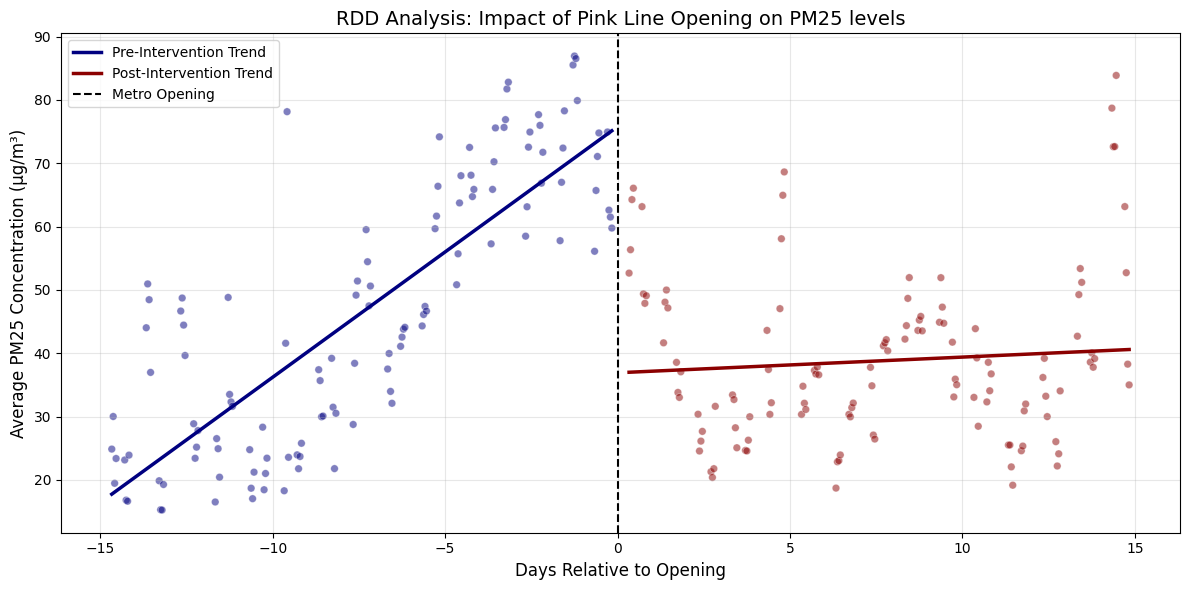


==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.738
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     221.2
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           2.82e-68
Time:                        09:09:32   Log-Likelihood:                -1237.0
No. Observations:                 240   AIC:                             2482.
Df Residuals:                     236   BIC:                             2496.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

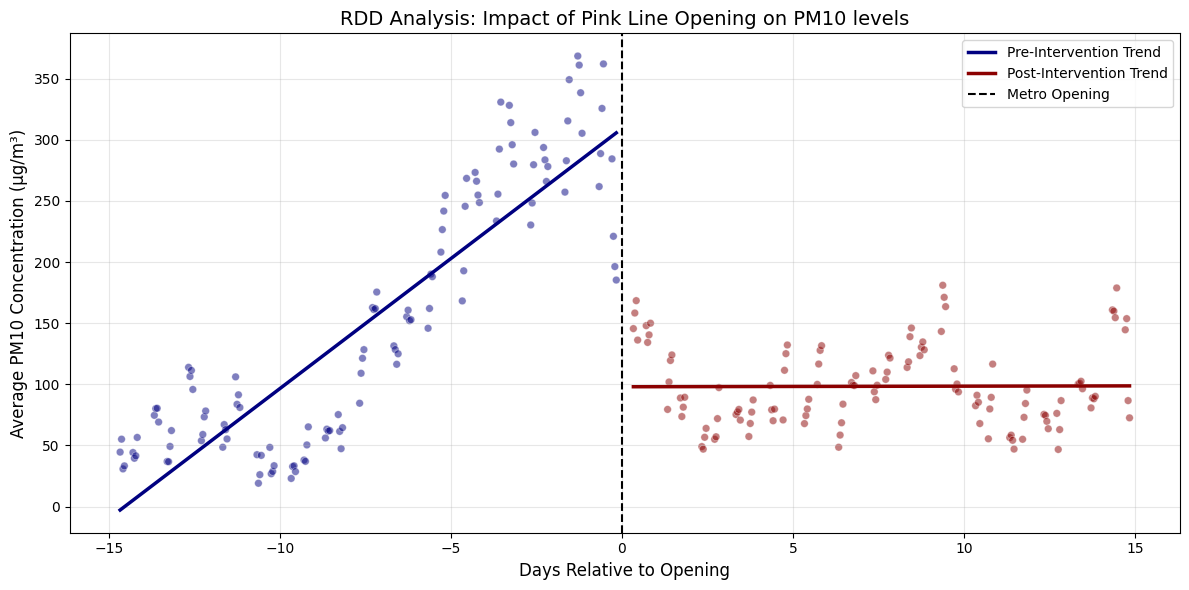

In [8]:
#Stage 2 Opening

stage_2_stations = [
    "R K Puram",
    "Nehru Nagar",
    "JawaharLal Nehru Stadium",
    # "Sirifort",
    # "Lodhi Garden",
    "Sri Aurbindo Marg",
    "CRRI Mathura Road",
    "Major Dhyan Chand National Stadium"
]

INTERVENTION_DATE_S2 = datetime.datetime(2018, 8, 6) 
WINDOW_DAYS = 15

stage2_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE_S2,
    window_days=WINDOW_DAYS,
    stations_list=stage_2_stations,
    years_to_load=[2018],
    base_path=BASE_PATH
)

if stage2_df is not None:
    output_filename = "Stage2_PeakHours_Pollution_Data.csv"
    # stage2_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: Stage 2 Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage2_df.head())
    print("\nDataframe Info:")
    print(stage2_df.info())
    df_pm25_s2 = stage2_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10_s2 = stage2_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    # Rename columns for statsmodels formula compatibility
    df_pm25_s2 = df_pm25_s2.rename(columns={'PM2.5': 'PM25'})
    df_pm10_s2 = df_pm10_s2.rename(columns={'PM10': 'PM10'})

    run_and_plot_aggregated_rdd(df_pm25_s2, 'PM25', INTERVENTION_DATE_S2)
    run_and_plot_aggregated_rdd(df_pm10_s2, 'PM10', INTERVENTION_DATE_S2)
else:
    print("\nFAILURE: No data was loaded.")
    


PROCESSING DATA
Intervention Date: 2018-07-25
Window: 15 days (Period: 2018-07-10 to 2018-08-09)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
R K Puram                 | 240      | 0 (0.0%)               | 4 (1.7%)              
Nehru Nagar               | 240      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 240      | 9 (3.8%)               | 6 (2.5%)              
Sri Aurbindo Marg         | 240      | 1 (0.4%)               | 0 (0.0%)              
CRRI Mathura Road         | 240      | 0 (0.0%)               | 1 (0.4%)              
Major Dhyan Chand National Stadium | 240      | 0 (0.0%)               | 0 (0.0%)              

SUCCESS: Stage 2 Data saved to Stage2_PeakHours_Pollution_Data.csv

Dataframe Head:
            TimeStamp  PM2.5   PM10 StationName
0 2018-07-10 08:00:00   39.0  102.0   R K Puram
1 2018-07-10 09:00:00   67.0   91.0   R K Puram
2 2018-07-10 10:00:00   50.0  111.0   R K Puram
3 2018-

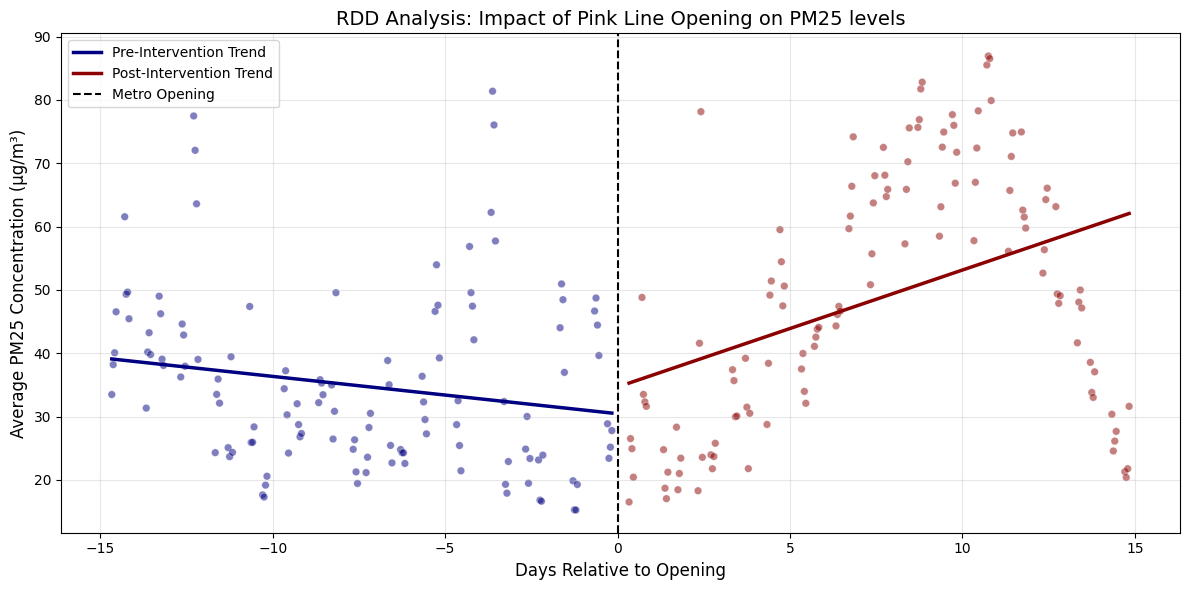


==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.344
Model:                            OLS   Adj. R-squared:                  0.335
Method:                 Least Squares   F-statistic:                     41.18
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           1.94e-21
Time:                        09:09:32   Log-Likelihood:                -1355.3
No. Observations:                 240   AIC:                             2719.
Df Residuals:                     236   BIC:                             2733.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

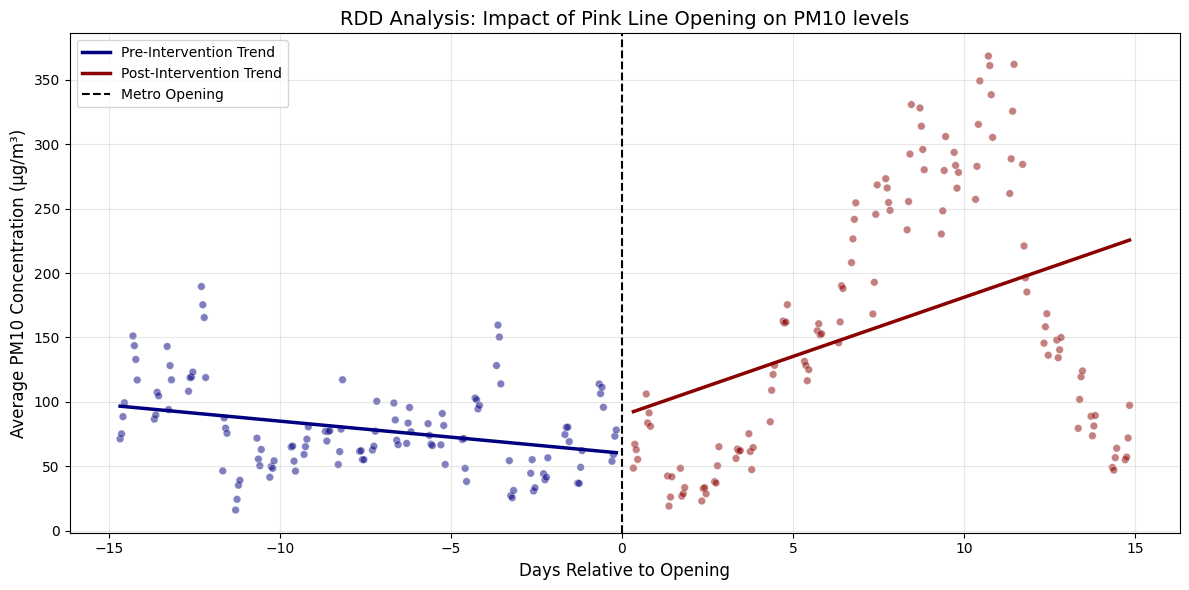

Running Treatment vs Control Comparison for Stage 2 (South Delhi)...
Loading Treatment Data (6 stations)...

PROCESSING DATA
Intervention Date: 2018-08-06
Window: 15 days (Period: 2018-07-22 to 2018-08-21)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
R K Puram                 | 240      | 0 (0.0%)               | 0 (0.0%)              
Nehru Nagar               | 240      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 240      | 6 (2.5%)               | 3 (1.2%)              
Sri Aurbindo Marg         | 240      | 0 (0.0%)               | 0 (0.0%)              
CRRI Mathura Road         | 240      | 0 (0.0%)               | 0 (0.0%)              
Major Dhyan Chand National Stadium | 240      | 0 (0.0%)               | 0 (0.0%)              
Loading Control Data (6 stations)...

PROCESSING DATA
Intervention Date: 2018-08-06
Window: 15 days (Period: 2018-07-22 to 2018-08-21)
STATION NAME              | ROWS     | MI

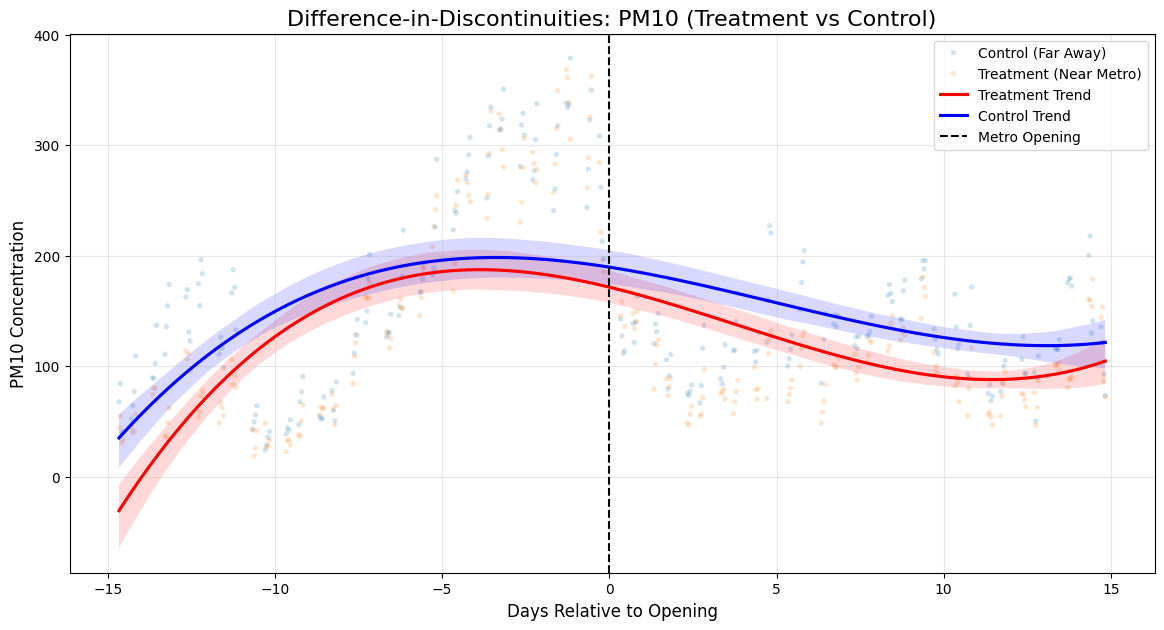

Loading Treatment Data (6 stations)...

PROCESSING DATA
Intervention Date: 2018-08-06
Window: 15 days (Period: 2018-07-22 to 2018-08-21)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
R K Puram                 | 240      | 0 (0.0%)               | 0 (0.0%)              
Nehru Nagar               | 240      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 240      | 6 (2.5%)               | 3 (1.2%)              
Sri Aurbindo Marg         | 240      | 0 (0.0%)               | 0 (0.0%)              
CRRI Mathura Road         | 240      | 0 (0.0%)               | 0 (0.0%)              
Major Dhyan Chand National Stadium | 240      | 0 (0.0%)               | 0 (0.0%)              
Loading Control Data (6 stations)...

PROCESSING DATA
Intervention Date: 2018-08-06
Window: 15 days (Period: 2018-07-22 to 2018-08-21)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Anand Vihar            

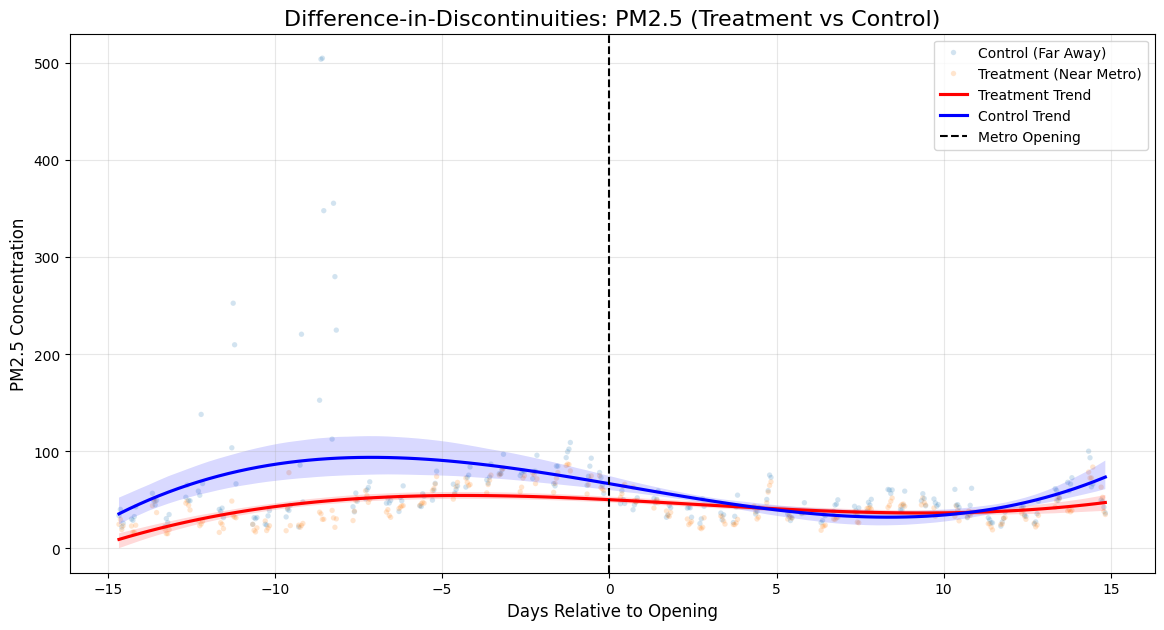

In [ ]:
#Stage 2 Opening

stage_2_stations = [
    "R K Puram",
    "Nehru Nagar",
    "JawaharLal Nehru Stadium",
    # "Sirifort",
    # "Lodhi Garden",
    "Sri Aurbindo Marg",
    "CRRI Mathura Road",
    "Major Dhyan Chand National Stadium"
]

INTERVENTION_DATE_S2 = datetime.datetime(2018, 7, 25) 
WINDOW_DAYS = 15

stage2_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE_S2,
    window_days=WINDOW_DAYS,
    stations_list=stage_2_stations,
    years_to_load=[2018],
    base_path=BASE_PATH
)

if stage2_df is not None:
    output_filename = "Stage2_PeakHours_Pollution_Data.csv"
    # stage2_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: Stage 2 Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage2_df.head())
    print("\nDataframe Info:")
    print(stage2_df.info())
    df_pm25_s2 = stage2_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10_s2 = stage2_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    # Rename columns for statsmodels formula compatibility
    df_pm25_s2 = df_pm25_s2.rename(columns={'PM2.5': 'PM25'})
    df_pm10_s2 = df_pm10_s2.rename(columns={'PM10': 'PM10'})

    run_and_plot_aggregated_rdd(df_pm25_s2, 'PM25', INTERVENTION_DATE_S2)
    run_and_plot_aggregated_rdd(df_pm10_s2, 'PM10', INTERVENTION_DATE_S2)
else:
    print("\nFAILURE: No data was loaded.")

import pandas as pd
import datetime
import matplotlib.pyplot as plt
import seaborn as sns

# Reuse the same function (no need to redefine if already in memory)
# If you need to redefine it, paste the function definition here.

# --- CONFIGURATION FOR STAGE 2 ---

# Intervention: August 6, 2018 (Monsoon Season)
INTERVENTION_DATE_S2 = datetime.datetime(2018, 8, 6)

# 1. TREATMENT GROUP (South Delhi - Close to Pink Line Stage 2)
# These stations are near Moti Bagh, INA, Lajpat Nagar
treat_list_s2 = [
    "R K Puram", 
    "Nehru Nagar", 
    "JawaharLal Nehru Stadium", 
    "Sri Aurbindo Marg", 
    "CRRI Mathura Road",
    "Major Dhyan Chand National Stadium"
]

# 2. CONTROL GROUP (Far from South Delhi)
# We use North, West, and East Delhi stations as controls.
# Note: Jahangirpuri/Punjabi Bagh already had Metro from Stage 1, so they are stable controls now.
control_list_s2 = [
    "Anand Vihar",    # Far East
    "JahangirPuri",   # Far North
    "Wazirpur",       # North West
    "Punjabi Bagh",   # West
    "Shadipur",       # West
    "IHBAS, Dilshad Garden" # Far East  
]

# --- RUN COMPARISON ---
print(f"Running Treatment vs Control Comparison for Stage 2 (South Delhi)...")
compare_treatment_control(treat_list_s2, control_list_s2, INTERVENTION_DATE_S2, 'PM10')
compare_treatment_control(treat_list_s2, control_list_s2, INTERVENTION_DATE_S2, 'PM2.5')
    


PROCESSING DATA
Intervention Date: 2018-10-31
Window: 15 days (Period: 2018-10-16 to 2018-11-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Anand Vihar               | 240      | 11 (4.6%)              | 10 (4.2%)             
Patparganj                | 240      | 3 (1.2%)               | 9 (3.8%)              
Vivek Vihar               | 240      | 8 (3.3%)               | 7 (2.9%)              
IHBAS                     | 240      | 8 (3.3%)               | 240 (100.0%)          
Chandi Chowk              | 240      | 240 (100.0%)           | 240 (100.0%)          

SUCCESS: Stage 3 Data saved to Stage3_PeakHours_Pollution_Data.csv

Dataframe Head:
            TimeStamp   PM2.5    PM10  StationName
0 2018-10-16 08:00:00  205.25  567.75  Anand Vihar
1 2018-10-16 09:00:00  150.50  432.75  Anand Vihar
2 2018-10-16 10:00:00  121.25  388.50  Anand Vihar
3 2018-10-16 11:00:00  118.75  395.25  Anand Vihar
4 2018-10-16 17:00:00  135.00  544.75  A

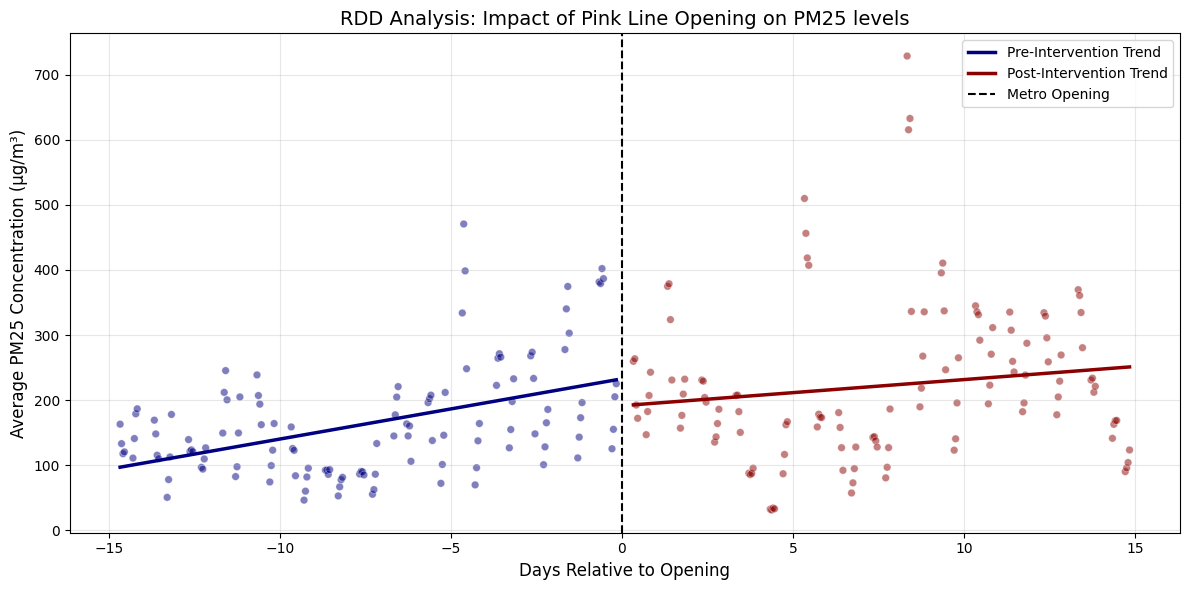


==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                  0.052
Method:                 Least Squares   F-statistic:                     5.360
Date:                Thu, 27 Nov 2025   Prob (F-statistic):            0.00138
Time:                        09:09:34   Log-Likelihood:                -1516.0
No. Observations:                 238   AIC:                             3040.
Df Residuals:                     234   BIC:                             3054.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

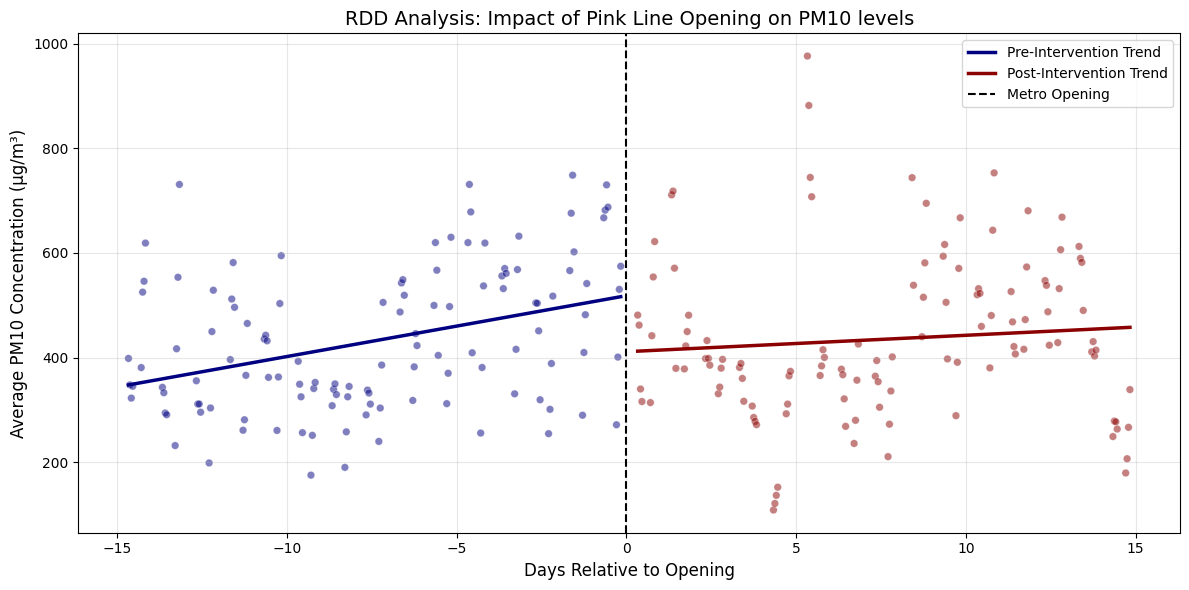

In [10]:
# ==========================================
# STAGE 3: TRILOKPURI SANJAY LAKE TO SHIV VIHAR
# ==========================================

# 1. Define Stage 3 Stations (Stations within 5km of the new section)
# Based on previous proximity analysis
stage_3_stations = [
    "Anand Vihar",
    "Patparganj",
    "Vivek Vihar",
    "IHBAS",        # Matches "IHBAS, Dilshad Garden"
    "Chandi Chowk"  # Matches "Chandi Chowk, Delhi - IITM"
]

# 2. Define Intervention Parameters
# Opening Date: October 31, 2018
INTERVENTION_DATE_S3 = datetime.datetime(2018, 10, 31) 
WINDOW_DAYS = 15

# 3. Load Data for Stage 3
stage3_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE_S3,
    window_days=WINDOW_DAYS,
    stations_list=stage_3_stations,
    years_to_load=[2018],
    base_path=BASE_PATH
)

if stage3_df is not None:
    output_filename = "Stage3_PeakHours_Pollution_Data.csv"
    # stage3_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: Stage 3 Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage3_df.head())
    print("\nDataframe Info:")
    print(stage3_df.info())
    # 4. Prepare Data for Analysis
    df_pm25_s3 = stage3_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10_s3 = stage3_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    df_pm25_s3 = df_pm25_s3.rename(columns={'PM2.5': 'PM25'})
    df_pm10_s3 = df_pm10_s3.rename(columns={'PM10': 'PM10'})

    run_and_plot_aggregated_rdd(df_pm25_s3, 'PM25', INTERVENTION_DATE_S3)
    run_and_plot_aggregated_rdd(df_pm10_s3, 'PM10', INTERVENTION_DATE_S3)
else:
    print("\nFAILURE: No data was loaded.")


PROCESSING DATA
Intervention Date: 2018-11-30
Window: 15 days (Period: 2018-11-15 to 2018-12-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Anand Vihar               | 240      | 0 (0.0%)               | 0 (0.0%)              
Patparganj                | 240      | 0 (0.0%)               | 0 (0.0%)              
Vivek Vihar               | 240      | 2 (0.8%)               | 4 (1.7%)              
IHBAS                     | 240      | 20 (8.3%)              | 240 (100.0%)          
Chandi Chowk              | 240      | 240 (100.0%)           | 240 (100.0%)          

SUCCESS: Stage 3 Data saved to Stage3_PeakHours_Pollution_Data.csv

Dataframe Head:
            TimeStamp   PM2.5    PM10  StationName
0 2018-11-15 08:00:00  106.25  201.75  Anand Vihar
1 2018-11-15 09:00:00   83.75  183.00  Anand Vihar
2 2018-11-15 10:00:00   81.00  157.50  Anand Vihar
3 2018-11-15 11:00:00   98.75  195.00  Anand Vihar
4 2018-11-15 17:00:00  109.25  255.25  A

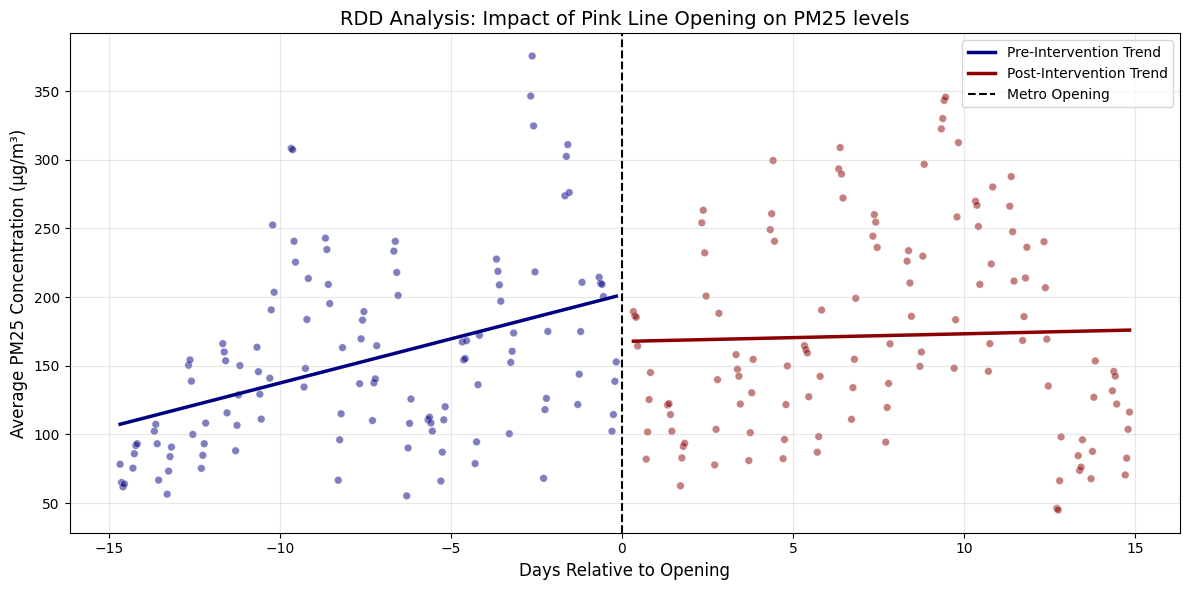


==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.188
Model:                            OLS   Adj. R-squared:                  0.178
Method:                 Least Squares   F-statistic:                     18.24
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           1.12e-10
Time:                        09:09:35   Log-Likelihood:                -1468.8
No. Observations:                 240   AIC:                             2946.
Df Residuals:                     236   BIC:                             2960.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

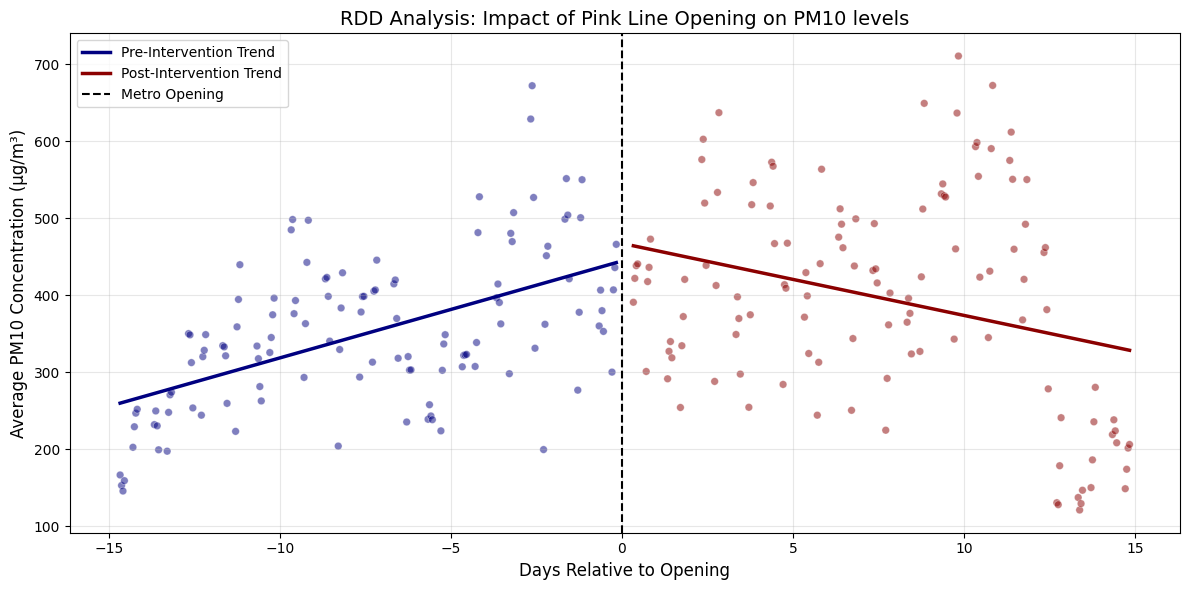

Running Treatment vs Control Comparison for Stage 3 (East Delhi)...
Loading Treatment Data (4 stations)...

PROCESSING DATA
Intervention Date: 2018-10-31
Window: 15 days (Period: 2018-10-16 to 2018-11-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Anand Vihar               | 240      | 11 (4.6%)              | 10 (4.2%)             
Patparganj                | 240      | 3 (1.2%)               | 9 (3.8%)              
Vivek Vihar               | 240      | 8 (3.3%)               | 7 (2.9%)              
IHBAS, Dilshad Garden     | 240      | 8 (3.3%)               | 240 (100.0%)          
Loading Control Data (6 stations)...

PROCESSING DATA
Intervention Date: 2018-10-31
Window: 15 days (Period: 2018-10-16 to 2018-11-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Dwarka Sector 8           | NO FILE  | -                      | -                     
Pusa                      | 240      | 44 (18.3%)  

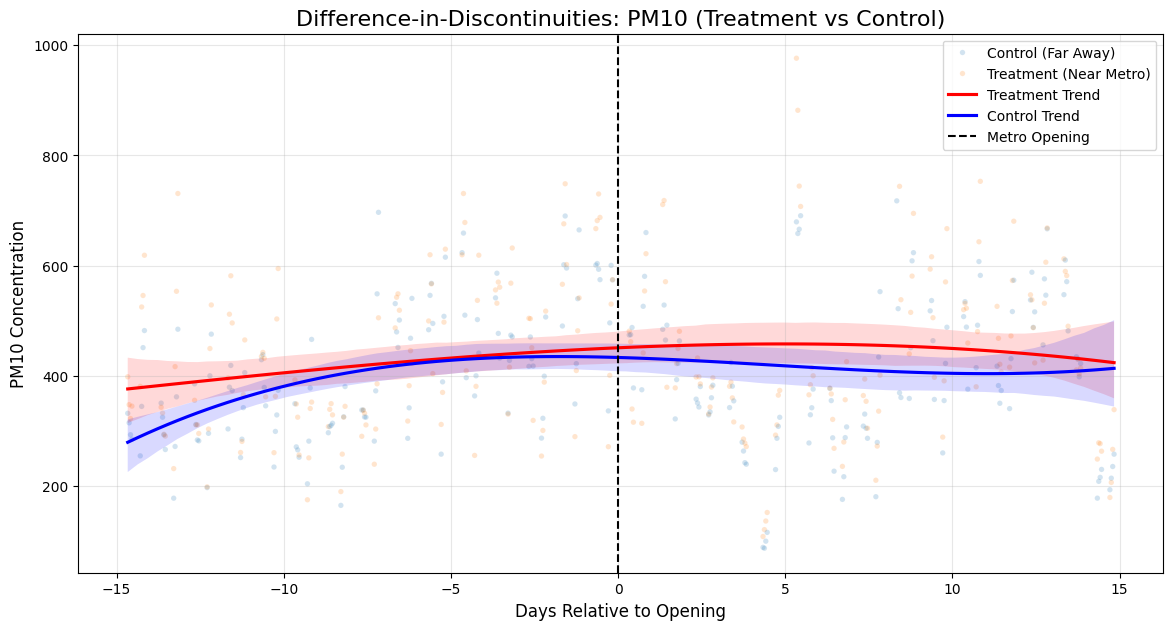

Loading Treatment Data (4 stations)...

PROCESSING DATA
Intervention Date: 2018-10-31
Window: 15 days (Period: 2018-10-16 to 2018-11-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Anand Vihar               | 240      | 11 (4.6%)              | 10 (4.2%)             
Patparganj                | 240      | 3 (1.2%)               | 9 (3.8%)              
Vivek Vihar               | 240      | 8 (3.3%)               | 7 (2.9%)              
IHBAS, Dilshad Garden     | 240      | 8 (3.3%)               | 240 (100.0%)          
Loading Control Data (6 stations)...

PROCESSING DATA
Intervention Date: 2018-10-31
Window: 15 days (Period: 2018-10-16 to 2018-11-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Dwarka Sector 8           | NO FILE  | -                      | -                     
Pusa                      | 240      | 44 (18.3%)             | 18 (7.5%)             
Shadipur                  | 240 

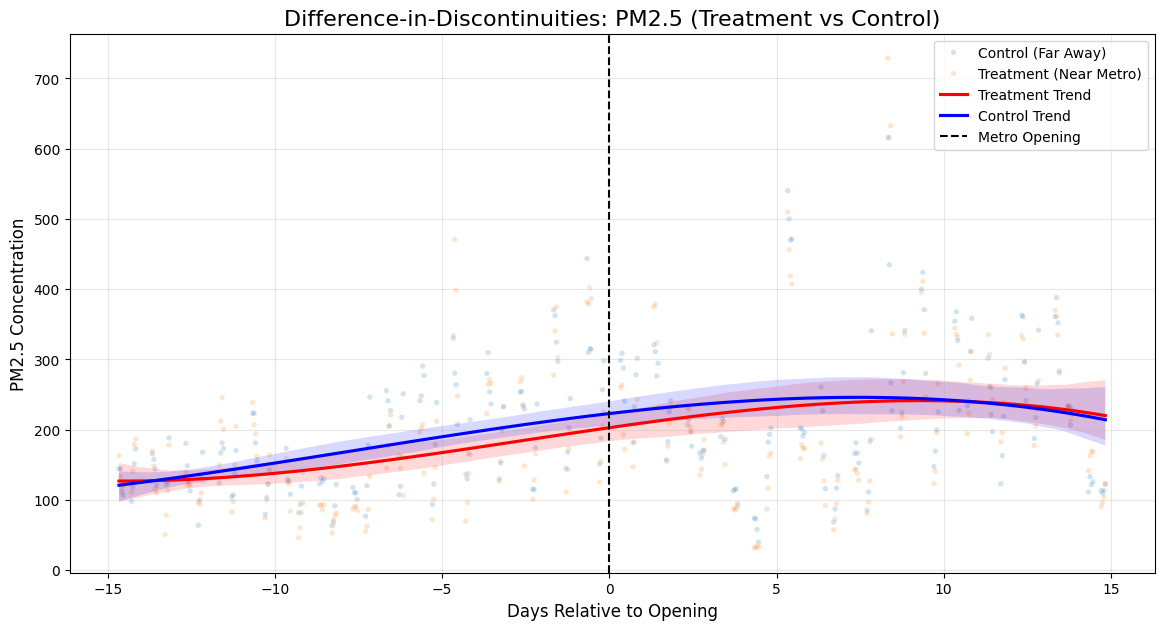

In [11]:
# ==========================================
# STAGE 3: TRILOKPURI SANJAY LAKE TO SHIV VIHAR
# ==========================================

# 1. Define Stage 3 Stations (Stations within 5km of the new section)
# Based on previous proximity analysis
stage_3_stations = [
    "Anand Vihar",
    "Patparganj",
    "Vivek Vihar",
    "IHBAS",        # Matches "IHBAS, Dilshad Garden"
    "Chandi Chowk"  # Matches "Chandi Chowk, Delhi - IITM"
]

# 2. Define Intervention Parameters
# Opening Date: October 31, 2018
INTERVENTION_DATE_S3 = datetime.datetime(2018, 11, 30) 
WINDOW_DAYS = 15

# 3. Load Data for Stage 3
stage3_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE_S3,
    window_days=WINDOW_DAYS,
    stations_list=stage_3_stations,
    years_to_load=[2018],
    base_path=BASE_PATH
)

if stage3_df is not None:
    output_filename = "Stage3_PeakHours_Pollution_Data.csv"
    # stage3_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: Stage 3 Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage3_df.head())
    print("\nDataframe Info:")
    print(stage3_df.info())
    # 4. Prepare Data for Analysis
    df_pm25_s3 = stage3_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10_s3 = stage3_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    df_pm25_s3 = df_pm25_s3.rename(columns={'PM2.5': 'PM25'})
    df_pm10_s3 = df_pm10_s3.rename(columns={'PM10': 'PM10'})

    run_and_plot_aggregated_rdd(df_pm25_s3, 'PM25', INTERVENTION_DATE_S3)
    run_and_plot_aggregated_rdd(df_pm10_s3, 'PM10', INTERVENTION_DATE_S3)
else:
    print("\nFAILURE: No data was loaded.")

# --- CONFIGURATION FOR STAGE 3 (EAST DELHI) ---

# Intervention: Oct 31, 2018
INTERVENTION_DATE_S3 = datetime.datetime(2018, 10, 31)

# 1. TREATMENT GROUP (East Delhi - The "Anand Vihar" Cluster)
treat_list_s3 = [
    "Anand Vihar", 
    "Patparganj", 
    "Vivek Vihar", 
    "IHBAS, Dilshad Garden"
]

# 2. CONTROL GROUP (West & South Delhi - Far from the new opening)
# Note: These areas were already connected or far away.
control_list_s3 = [
    "Dwarka Sector 8",
    "Pusa", 
    "Shadipur",
    "Punjabi Bagh", 
    "R K Puram",       # South Delhi (Already has metro)
    "Rohini"
]

# --- RUN COMPARISON ---
print(f"Running Treatment vs Control Comparison for Stage 3 (East Delhi)...")
# Note: Using PM10 because that's where your significant result is
compare_treatment_control(treat_list_s3, control_list_s3, INTERVENTION_DATE_S3, 'PM10')
compare_treatment_control(treat_list_s3, control_list_s3, INTERVENTION_DATE_S3, 'PM2.5')


PROCESSING DATA
Intervention Date: 2018-12-31
Window: 15 days (Period: 2018-12-16 to 2019-01-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Nehru Nagar               | 128      | 7 (5.5%)               | 8 (6.2%)              
Nehru Nagar               | 112      | 5 (4.5%)               | 5 (4.5%)              
JawaharLal Nehru Stadium  | 128      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 112      | 1 (0.9%)               | 5 (4.5%)              
Patparganj                | 128      | 0 (0.0%)               | 0 (0.0%)              
Patparganj                | 112      | 5 (4.5%)               | 5 (4.5%)              
CRRI Mathura Road         | 128      | 0 (0.0%)               | 0 (0.0%)              
CRRI Mathura Road         | 112      | 0 (0.0%)               | 0 (0.0%)              
Sirifort                  | 128      | 0 (0.0%)               | 0 (0.0%)              
Sirifort                  | 112 

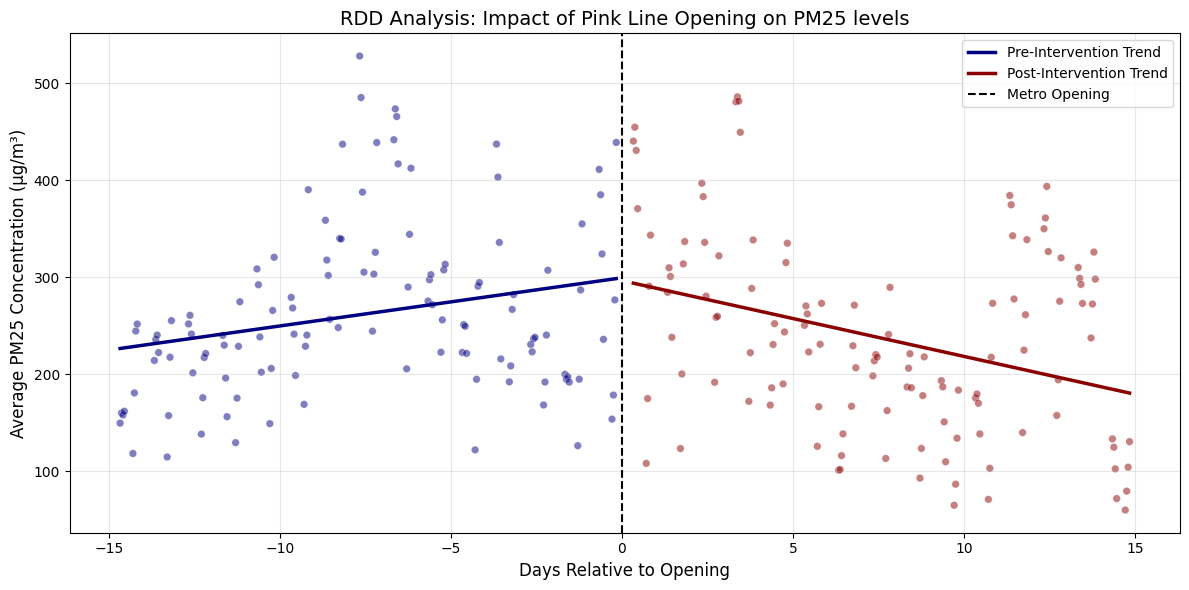


RUNNING RDD FOR STAGE 4 (PM10)

==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.161
Model:                            OLS   Adj. R-squared:                  0.150
Method:                 Least Squares   F-statistic:                     15.11
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           4.98e-09
Time:                        09:09:38   Log-Likelihood:                -1491.0
No. Observations:                 240   AIC:                             2990.
Df Residuals:                     236   BIC:                             3004.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------

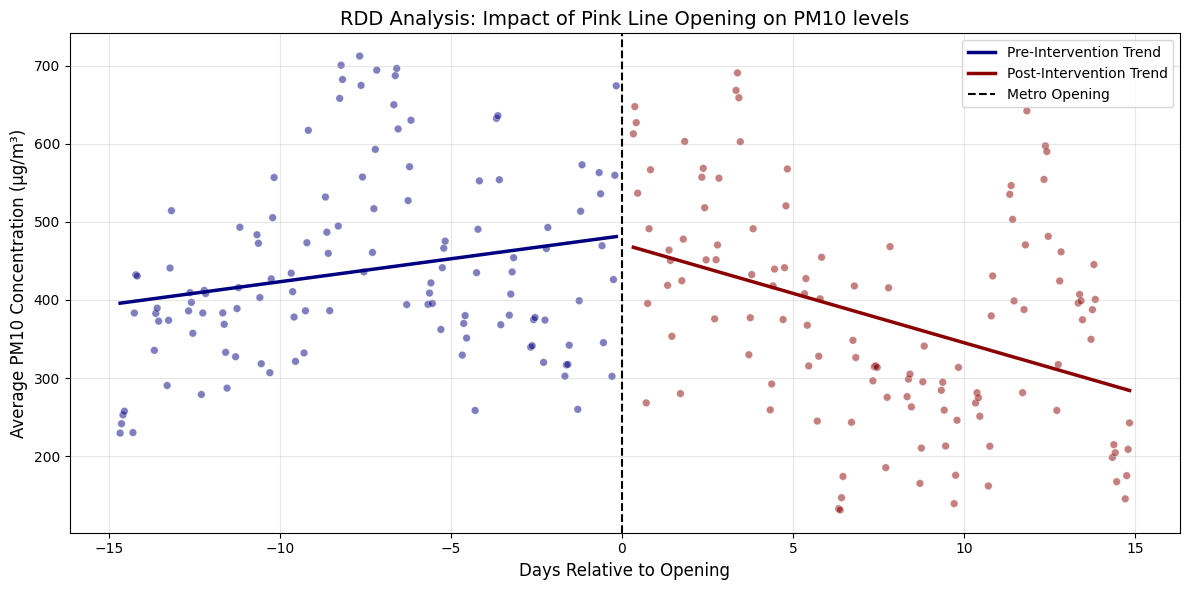

In [12]:
# ==========================================
# STAGE 4: LAJPAT NAGAR TO MAYUR VIHAR POCKET 1
# ==========================================

# 1. Define Stage 4 Stations (Stations within 5km of the new section)
# Based on previous proximity analysis
stage_4_stations = [
    "Nehru Nagar",
    "JawaharLal Nehru Stadium",
    "Patparganj",
    "CRRI Mathura Road",
    # "Lodhi Garden",
    "Sirifort",
    "Okhla Phase 2",
    "ITO",
    "Major Dhyan Chand National Stadium",
    "Sri Aurbindo Marg"
]

INTERVENTION_DATE_S4 = datetime.datetime(2018, 12, 31) 
WINDOW_DAYS = 15

# 3. Load Data for Stage 4
stage4_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE_S4,
    window_days=WINDOW_DAYS,
    stations_list=stage_4_stations,
    years_to_load=[2018,2019],
    base_path=BASE_PATH
)

if stage4_df is not None:
    output_filename = "Stage4_PeakHours_Pollution_Data.csv"
    # stage4_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: Stage 4 Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage4_df.head())
    print("\nDataframe Info:")
    print(stage4_df.info())
    
    # 4. Prepare Data for Analysis
    # Create separate clean DataFrames for PM2.5 and PM10
    df_pm25_s4 = stage4_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10_s4 = stage4_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    # Rename columns for statsmodels formula compatibility
    df_pm25_s4 = df_pm25_s4.rename(columns={'PM2.5': 'PM25'})
    df_pm10_s4 = df_pm10_s4.rename(columns={'PM10': 'PM10'})

    # 5. Run RDD Analysis
    print("\n" + "="*40)
    print("RUNNING RDD FOR STAGE 4 (PM2.5)")
    print("="*40)
    run_and_plot_aggregated_rdd(df_pm25_s4, 'PM25', INTERVENTION_DATE_S4)

    print("\n" + "="*40)
    print("RUNNING RDD FOR STAGE 4 (PM10)")
    print("="*40)
    run_and_plot_aggregated_rdd(df_pm10_s4, 'PM10', INTERVENTION_DATE_S4)

else:
    print("\nFAILURE: No data was loaded for Stage 4.")


PROCESSING DATA
Intervention Date: 2018-11-30
Window: 15 days (Period: 2018-11-15 to 2018-12-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Nehru Nagar               | 240      | 0 (0.0%)               | 8 (3.3%)              
Nehru Nagar               | 0        | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 240      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 0        | 0 (0.0%)               | 0 (0.0%)              
Patparganj                | 240      | 0 (0.0%)               | 0 (0.0%)              
Patparganj                | 0        | 0 (0.0%)               | 0 (0.0%)              
CRRI Mathura Road         | 240      | 0 (0.0%)               | 9 (3.8%)              
CRRI Mathura Road         | 0        | 0 (0.0%)               | 0 (0.0%)              
Sirifort                  | 240      | 10 (4.2%)              | 10 (4.2%)             
Sirifort                  | 0   

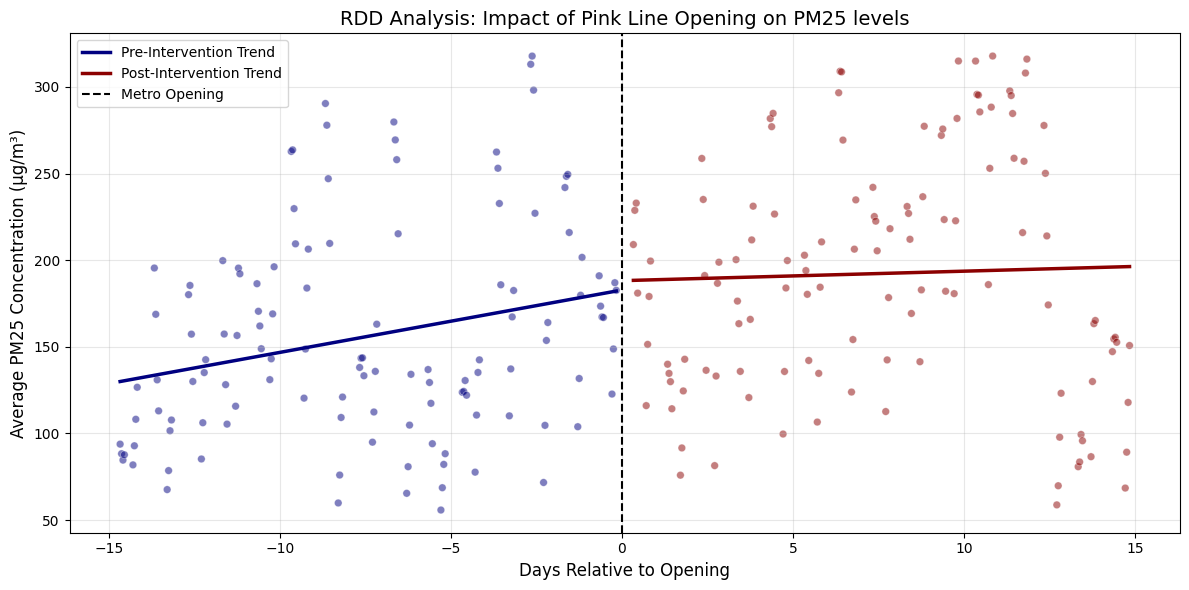


RUNNING RDD FOR STAGE 4 (PM10)

==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.196
Model:                            OLS   Adj. R-squared:                  0.186
Method:                 Least Squares   F-statistic:                     19.21
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           3.52e-11
Time:                        09:09:38   Log-Likelihood:                -1410.0
No. Observations:                 240   AIC:                             2828.
Df Residuals:                     236   BIC:                             2842.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------

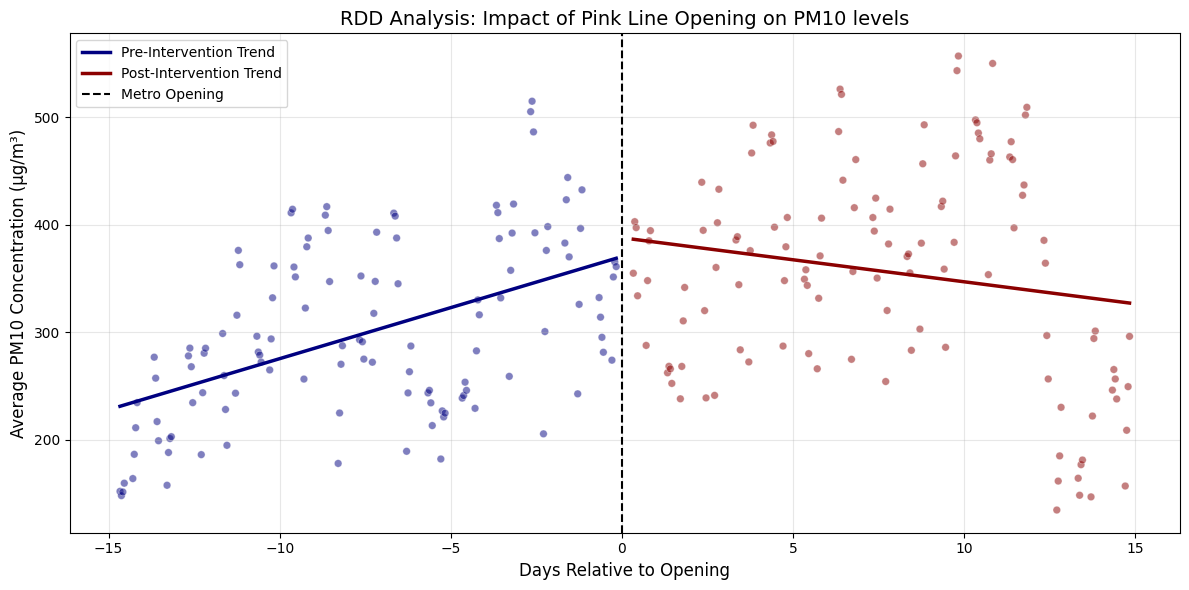

Loading Treatment Data (5 stations)...

PROCESSING DATA
Intervention Date: 2018-12-31
Window: 15 days (Period: 2018-12-16 to 2019-01-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Nehru Nagar               | 128      | 7 (5.5%)               | 8 (6.2%)              
Nehru Nagar               | 112      | 5 (4.5%)               | 5 (4.5%)              
Patparganj                | 128      | 0 (0.0%)               | 0 (0.0%)              
Patparganj                | 112      | 5 (4.5%)               | 5 (4.5%)              
Okhla Phase 2             | 128      | 0 (0.0%)               | 0 (0.0%)              
Okhla Phase 2             | 112      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 128      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 112      | 1 (0.9%)               | 5 (4.5%)              
CRRI Mathura Road         | 128      | 0 (0.0%)               | 0 (0.0%)        

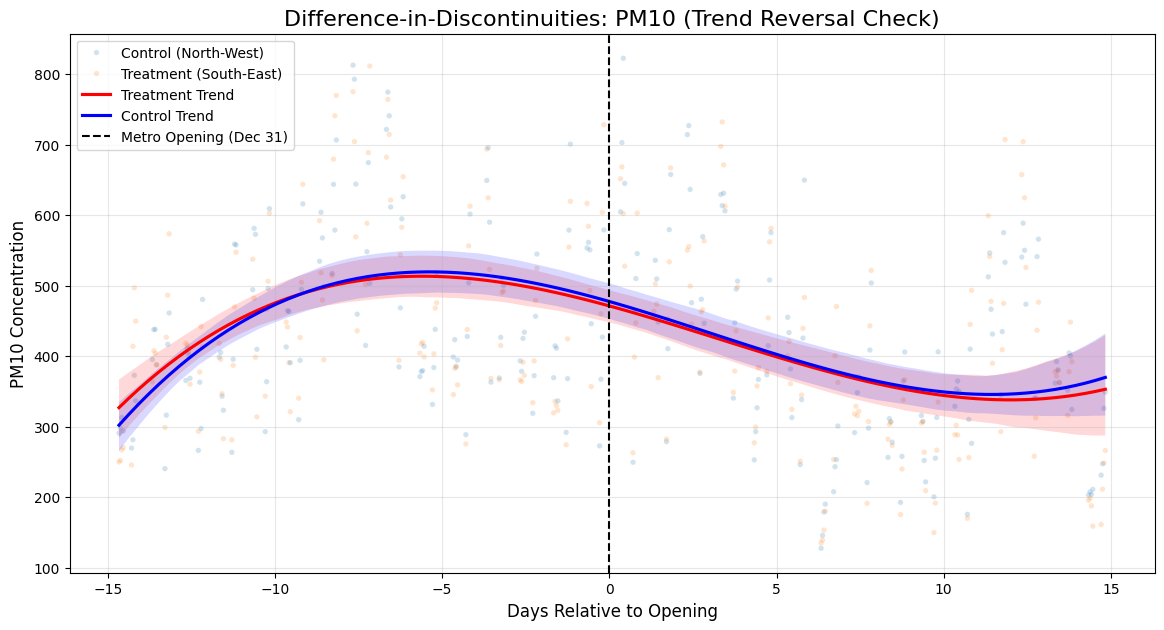

Loading Treatment Data (5 stations)...

PROCESSING DATA
Intervention Date: 2018-12-31
Window: 15 days (Period: 2018-12-16 to 2019-01-15)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Nehru Nagar               | 128      | 7 (5.5%)               | 8 (6.2%)              
Nehru Nagar               | 112      | 5 (4.5%)               | 5 (4.5%)              
Patparganj                | 128      | 0 (0.0%)               | 0 (0.0%)              
Patparganj                | 112      | 5 (4.5%)               | 5 (4.5%)              
Okhla Phase 2             | 128      | 0 (0.0%)               | 0 (0.0%)              
Okhla Phase 2             | 112      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 128      | 0 (0.0%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 112      | 1 (0.9%)               | 5 (4.5%)              
CRRI Mathura Road         | 128      | 0 (0.0%)               | 0 (0.0%)        

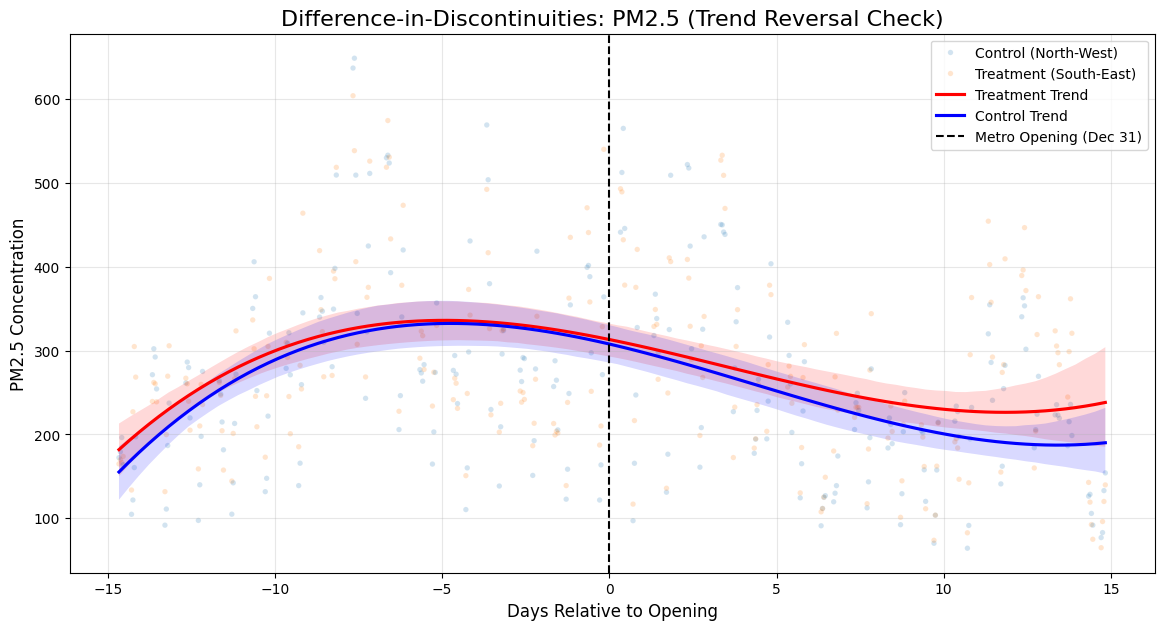

In [13]:
# ==========================================
# STAGE 4: LAJPAT NAGAR TO MAYUR VIHAR POCKET 1
# ==========================================

# 1. Define Stage 4 Stations (Stations within 5km of the new section)
# Based on previous proximity analysis
stage_4_stations = [
    "Nehru Nagar",
    "JawaharLal Nehru Stadium",
    "Patparganj",
    "CRRI Mathura Road",
    # "Lodhi Garden",
    "Sirifort",
    "Okhla Phase 2",
    "ITO",
    "Major Dhyan Chand National Stadium",
    "Sri Aurbindo Marg"
]

INTERVENTION_DATE_S4 = datetime.datetime(2018, 11, 30) 
WINDOW_DAYS = 15

# 3. Load Data for Stage 4
stage4_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE_S4,
    window_days=WINDOW_DAYS,
    stations_list=stage_4_stations,
    years_to_load=[2018,2019],
    base_path=BASE_PATH
)

if stage4_df is not None:
    output_filename = "Stage4_PeakHours_Pollution_Data.csv"
    # stage4_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: Stage 4 Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage4_df.head())
    print("\nDataframe Info:")
    print(stage4_df.info())
    
    # 4. Prepare Data for Analysis
    # Create separate clean DataFrames for PM2.5 and PM10
    df_pm25_s4 = stage4_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10_s4 = stage4_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    # Rename columns for statsmodels formula compatibility
    df_pm25_s4 = df_pm25_s4.rename(columns={'PM2.5': 'PM25'})
    df_pm10_s4 = df_pm10_s4.rename(columns={'PM10': 'PM10'})

    # 5. Run RDD Analysis
    print("\n" + "="*40)
    print("RUNNING RDD FOR STAGE 4 (PM2.5)")
    print("="*40)
    run_and_plot_aggregated_rdd(df_pm25_s4, 'PM25', INTERVENTION_DATE_S4)

    print("\n" + "="*40)
    print("RUNNING RDD FOR STAGE 4 (PM10)")
    print("="*40)
    run_and_plot_aggregated_rdd(df_pm10_s4, 'PM10', INTERVENTION_DATE_S4)

else:
    print("\nFAILURE: No data was loaded for Stage 4.")

# --- CONFIGURATION FOR STAGE 4 (SOUTH-EAST CONNECTOR) ---

# Intervention: Dec 31, 2018
INTERVENTION_DATE_S4 = datetime.datetime(2018, 12, 31)

# 1. TREATMENT GROUP (South-East Delhi - The Ashram/Mayur Vihar Cluster)
treat_list_s4 = [
    "Nehru Nagar",
    "Patparganj", 
    "Okhla Phase 2",
    "JawaharLal Nehru Stadium",
    "CRRI Mathura Road"
]

# 2. CONTROL GROUP (North & West Delhi - Far away)
# These areas are not affected by the Ashram/Ring Road traffic.
control_list_s4 = [
    "Punjabi Bagh", 
    "Rohini", 
    "Dwarka Sector 8",
    "Pusa",
    "Mundka" 
]
# --- RUN COMPARISON ---

def compare_treatment_controlnew(treatment_stations, control_stations, intervention_date, pollutant='PM10'):
    """
    Plots Treatment vs Control stations to visualize the causal gap.
    """
    # FIX: Load both 2018 and 2019 data to cover the Dec-Jan transition
    YEARS = [2018, 2019] 
    
    print(f"Loading Treatment Data ({len(treatment_stations)} stations)...")
    # Pass YEARS here instead of [2018]
    df_treat = load_pollution_data(PEAK_HOURS, intervention_date, WINDOW_DAYS, treatment_stations, YEARS)
    df_treat['Group'] = 'Treatment (South-East)'
    
    print(f"Loading Control Data ({len(control_stations)} stations)...")
    # Pass YEARS here instead of [2018]
    df_control = load_pollution_data(PEAK_HOURS, intervention_date, WINDOW_DAYS, control_stations, YEARS)
    df_control['Group'] = 'Control (North-West)'
    
    # Combine
    df_combined = pd.concat([df_treat, df_control])
    
    # Aggregate by Hour and Group
    df_agg = df_combined.groupby(['TimeStamp', 'Group'])[pollutant].mean().reset_index()
    df_agg['days_relative'] = (df_agg['TimeStamp'] - intervention_date).dt.total_seconds() / (24 * 3600)
    
    # Plot
    plt.figure(figsize=(14, 7))
    
    # Scatter points (faint)
    sns.scatterplot(data=df_agg, x='days_relative', y=pollutant, hue='Group', alpha=0.2, s=15)
    
    # Trend Lines (LOESS smooth)
    sns.regplot(data=df_agg[df_agg['Group']=='Treatment (South-East)'], x='days_relative', y=pollutant, 
                scatter=False, label='Treatment Trend', color='red', order=3)
    
    sns.regplot(data=df_agg[df_agg['Group']=='Control (North-West)'], x='days_relative', y=pollutant, 
                scatter=False, label='Control Trend', color='blue', order=3)
    
    plt.axvline(x=0, color='black', linestyle='--', label='Metro Opening (Dec 31)')
    plt.title(f"Difference-in-Discontinuities: {pollutant} (Trend Reversal Check)", fontsize=16)
    plt.ylabel(f"{pollutant} Concentration", fontsize=12)
    plt.xlabel("Days Relative to Opening", fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# --- RE-RUN FOR STAGE 4 ---
INTERVENTION_DATE_S4 = datetime.datetime(2018, 12, 31)

treat_list_s4 = ["Nehru Nagar", "Patparganj", "Okhla Phase 2", "JawaharLal Nehru Stadium", "CRRI Mathura Road"]
control_list_s4 = ["Punjabi Bagh", "Rohini", "Dwarka Sector 8", "Pusa", "Mundka"]

compare_treatment_controlnew(treat_list_s4, control_list_s4, INTERVENTION_DATE_S4, 'PM10')
compare_treatment_controlnew(treat_list_s4, control_list_s4, INTERVENTION_DATE_S4, 'PM2.5')


PROCESSING DATA
Intervention Date: 2021-08-06
Window: 15 days (Period: 2021-07-22 to 2021-08-21)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
North Campus              | 240      | 89 (37.1%)             | 86 (35.8%)            
Punjabi Bagh              | 240      | 1 (0.4%)               | 0 (0.0%)              
JawaharLal Nehru Stadium  | 240      | 4 (1.7%)               | 4 (1.7%)              
IHBAS                     | 240      | 17 (7.1%)              | 15 (6.2%)             
JahangirPuri              | 240      | 10 (4.2%)              | 10 (4.2%)             
R K Puram                 | 240      | 9 (3.8%)               | 44 (18.3%)            
Shadipur                  | 240      | 10 (4.2%)              | 11 (4.6%)             
Pusa                      | 240      | 14 (5.8%)              | 4 (1.7%)              
Chandi Chowk              | 240      | 10 (4.2%)              | 11 (4.6%)             
Ashok Vihar               | 240 

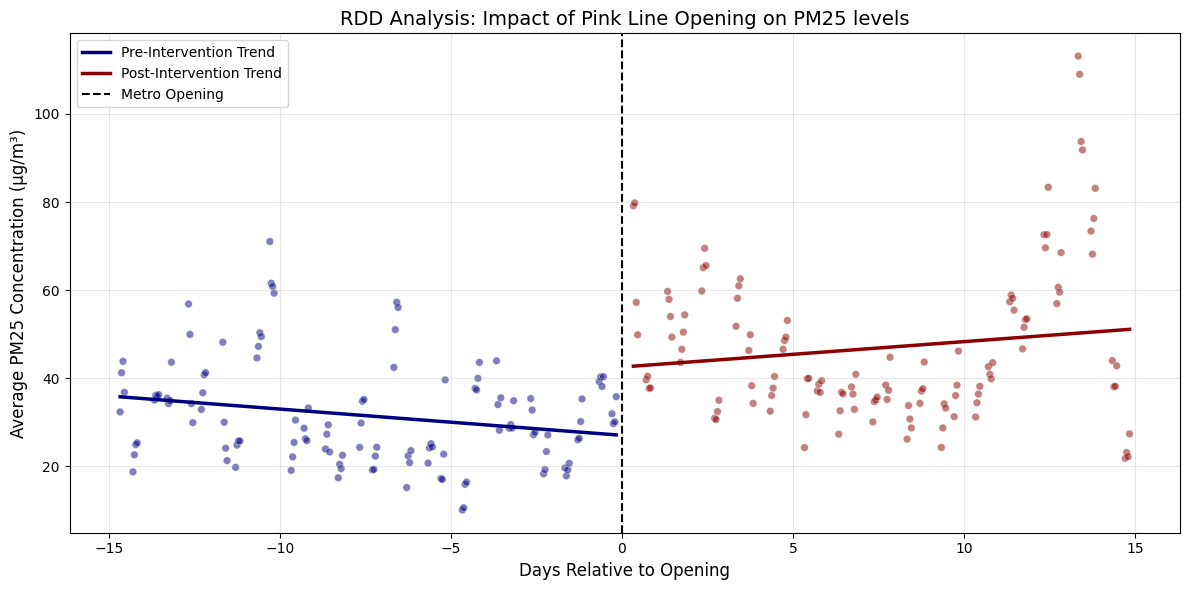


==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.557
Model:                            OLS   Adj. R-squared:                  0.551
Method:                 Least Squares   F-statistic:                     98.86
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           1.80e-41
Time:                        09:09:42   Log-Likelihood:                -1179.0
No. Observations:                 240   AIC:                             2366.
Df Residuals:                     236   BIC:                             2380.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

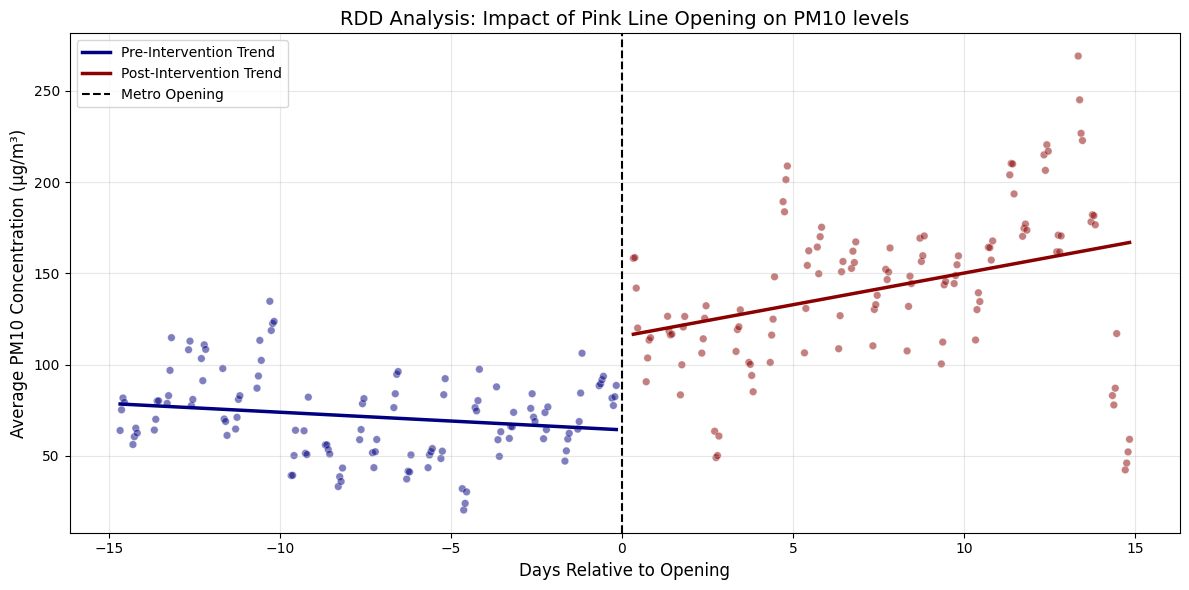

In [14]:
# ==========================================
# Combined : GAP COMPLETION (TRILOKPURI - MAYUR VIHAR PKT 1)
# ==========================================
stage_5_stations = [
    "Patparganj",   # Closest station (approx 2km from gap)
]

all_stations = []
all_stations += stage_1_stations
all_stations += stage_2_stations
all_stations += stage_3_stations
all_stations += stage_4_stations
all_stations += stage_5_stations
all_stations = list(set(all_stations))

INTERVENTION_DATE_S5 = datetime.datetime(2021, 8, 6) 
WINDOW_DAYS = 15

stage5_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE_S5,
    window_days=WINDOW_DAYS,
    stations_list=all_stations,
    years_to_load=[2021],
    base_path=BASE_PATH
)

if stage5_df is not None:
    output_filename = "All_Stations_PeakHours_Pollution_Data_Combined.csv"
    # stage5_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: All Stations Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage5_df.head())
    print("\nDataframe Info:")
    print(stage5_df.info())
    
    df_pm25_s5 = stage5_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10_s5 = stage5_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    df_pm25_s5 = df_pm25_s5.rename(columns={'PM2.5': 'PM25'})
    df_pm10_s5 = df_pm10_s5.rename(columns={'PM10': 'PM10'})

    run_and_plot_aggregated_rdd(df_pm25_s5, 'PM25', INTERVENTION_DATE_S5)
    run_and_plot_aggregated_rdd(df_pm10_s5, 'PM10', INTERVENTION_DATE_S5)

else:
    print("\nFAILURE: No data was loaded for Stage 5.")


PROCESSING DATA
Intervention Date: 2021-09-06
Window: 15 days (Period: 2021-08-22 to 2021-09-21)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
North Campus              | 240      | 7 (2.9%)               | 7 (2.9%)              
Punjabi Bagh              | 240      | 3 (1.2%)               | 5 (2.1%)              
JawaharLal Nehru Stadium  | 240      | 8 (3.3%)               | 11 (4.6%)             
IHBAS                     | 240      | 21 (8.8%)              | 19 (7.9%)             
JahangirPuri              | 240      | 3 (1.2%)               | 3 (1.2%)              
R K Puram                 | 240      | 41 (17.1%)             | 11 (4.6%)             
Shadipur                  | 240      | 7 (2.9%)               | 6 (2.5%)              
Pusa                      | 240      | 15 (6.2%)              | 0 (0.0%)              
Chandi Chowk              | 240      | 42 (17.5%)             | 43 (17.9%)            
Ashok Vihar               | 240 

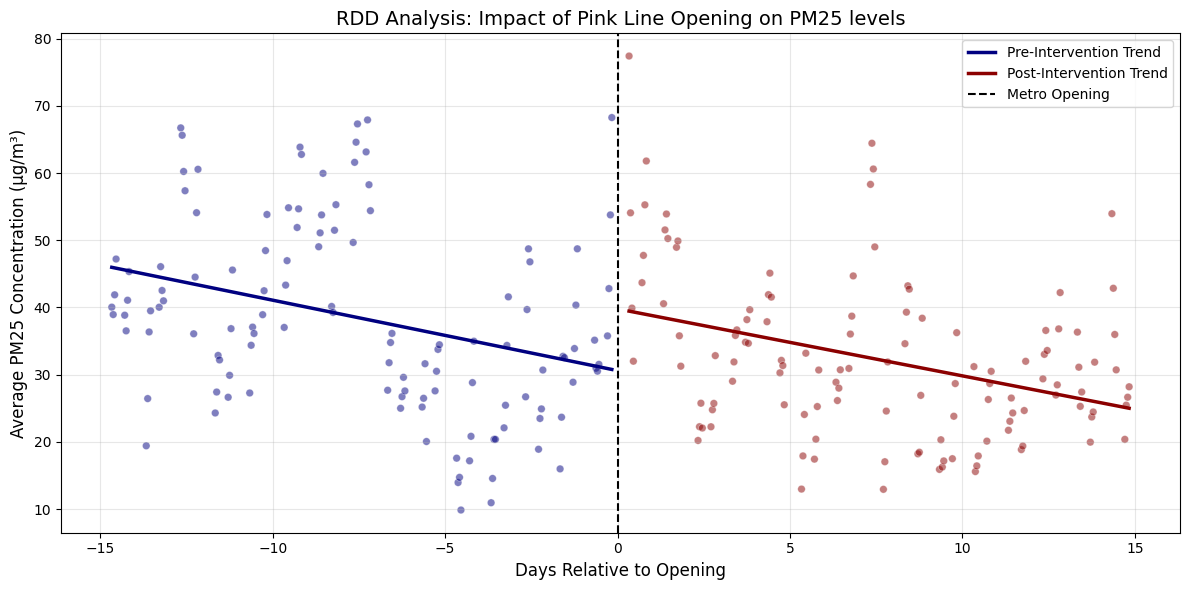


==================== RDD RESULTS: PM10 ====================
                            OLS Regression Results                            
Dep. Variable:                   PM10   R-squared:                       0.195
Model:                            OLS   Adj. R-squared:                  0.185
Method:                 Least Squares   F-statistic:                     19.10
Date:                Thu, 27 Nov 2025   Prob (F-statistic):           4.01e-11
Time:                        09:09:43   Log-Likelihood:                -1213.3
No. Observations:                 240   AIC:                             2435.
Df Residuals:                     236   BIC:                             2448.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

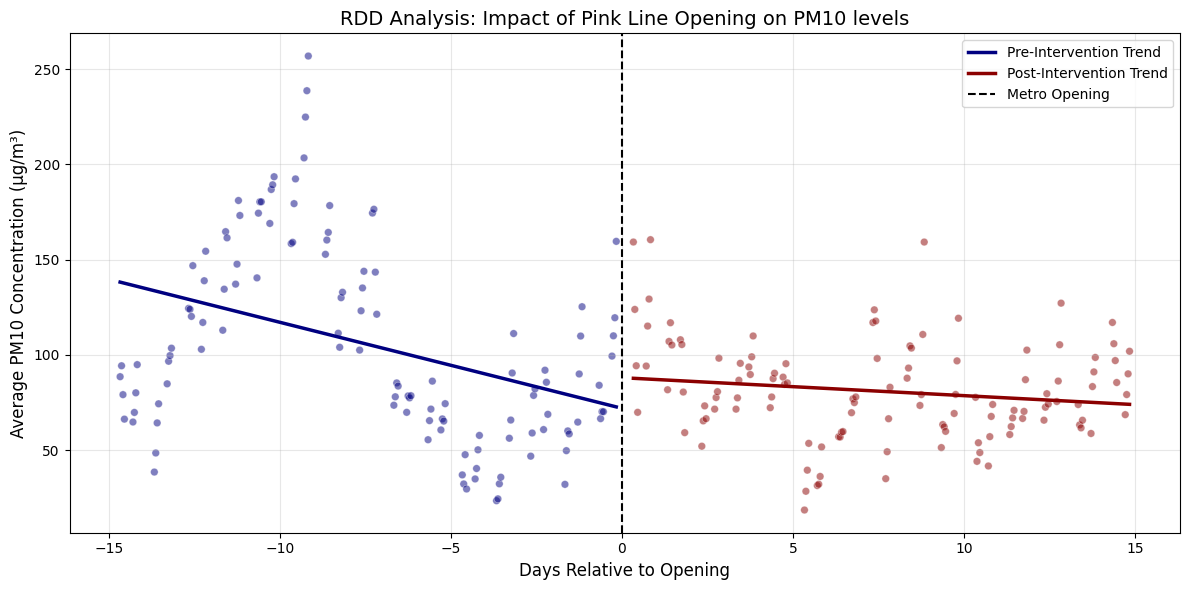

In [15]:
# ==========================================
# Combined : GAP COMPLETION (TRILOKPURI - MAYUR VIHAR PKT 1)
# ==========================================

all_stations = []
all_stations += stage_1_stations
all_stations += stage_2_stations
all_stations += stage_3_stations
all_stations += stage_4_stations
all_stations += stage_5_stations
all_stations = list(set(all_stations))

INTERVENTION_DATE_S5 = datetime.datetime(2021, 9, 6) 
WINDOW_DAYS = 15

stage5_df = load_pollution_data(
    peak_hours=PEAK_HOURS,
    intervention_date=INTERVENTION_DATE_S5,
    window_days=WINDOW_DAYS,
    stations_list=all_stations,
    years_to_load=[2021],
    base_path=BASE_PATH
)

if stage5_df is not None:
    output_filename = "All_Stations_PeakHours_Pollution_Data_Combined.csv"
    # stage5_df.to_csv(output_filename, index=False)
    print(f"\nSUCCESS: All Stations Data saved to {output_filename}")
    print("\nDataframe Head:")
    print(stage5_df.head())
    print("\nDataframe Info:")
    print(stage5_df.info())
    
    df_pm25_s5 = stage5_df[['TimeStamp', 'StationName', 'PM2.5']].dropna().copy()
    df_pm10_s5 = stage5_df[['TimeStamp', 'StationName', 'PM10']].dropna().copy()

    df_pm25_s5 = df_pm25_s5.rename(columns={'PM2.5': 'PM25'})
    df_pm10_s5 = df_pm10_s5.rename(columns={'PM10': 'PM10'})

    run_and_plot_aggregated_rdd(df_pm25_s5, 'PM25', INTERVENTION_DATE_S5)
    run_and_plot_aggregated_rdd(df_pm10_s5, 'PM10', INTERVENTION_DATE_S5)

else:
    print("\nFAILURE: No data was loaded for Stage 5.")


ROBUSTNESS CHECK FOR: PM25
--- Linear Model ---
Jump Coefficient: 9.1879
P-Value: 0.0074
R-Squared: 0.1616
--------------------
--- Quadratic Model ---
Jump Coefficient: 19.0487
P-Value: 0.0007
R-Squared: 0.1983
--------------------


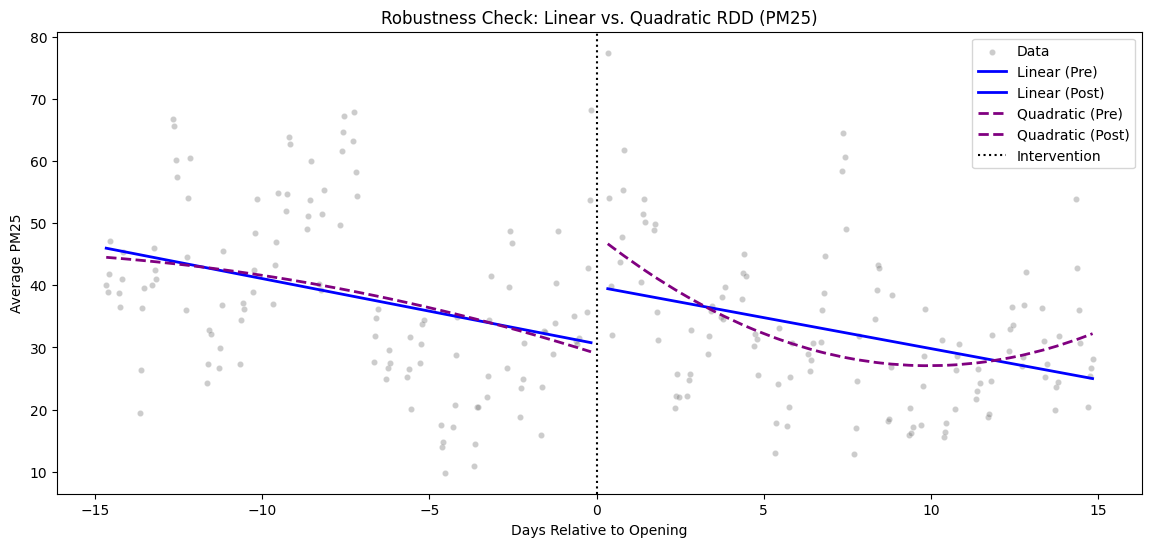

In [16]:
# ==========================================
# ROBUSTNESS CHECK: QUADRATIC RDD
# ==========================================

def run_robustness_rdd(df, pollutant_col, intervention_date):
    """
    Runs both Linear and Quadratic RDD models to check sensitivity.
    """
    print(f"\n{'='*50}")
    print(f"ROBUSTNESS CHECK FOR: {pollutant_col}")
    print(f"{'='*50}")

    # 1. Prepare Data
    df_agg = df.groupby('TimeStamp')[pollutant_col].mean().reset_index()
    df_agg['days_relative'] = (df_agg['TimeStamp'] - intervention_date).dt.total_seconds() / (24 * 3600)
    df_agg['days_sq'] = df_agg['days_relative'] ** 2  # Quadratic Term
    df_agg['treatment'] = (df_agg['days_relative'] >= 0).astype(int)

    # 2. Define Models
    formulas = {
        "Linear": f"{pollutant_col} ~ days_relative * treatment",
        "Quadratic": f"{pollutant_col} ~ (days_relative + days_sq) * treatment"
    }

    results = []

    # 3. Run Models & Plot
    plt.figure(figsize=(14, 6))
    
    # Plot Raw Data once
    sns.scatterplot(x='days_relative', y=pollutant_col, data=df_agg, color='grey', alpha=0.4, s=20, label='Data')

    colors = {'Linear': 'blue', 'Quadratic': 'purple'}
    linestyles = {'Linear': '-', 'Quadratic': '--'}

    for name, formula in formulas.items():
        try:
            model = smf.ols(formula=formula, data=df_agg).fit(cov_type='HC3')
            
            # Extract Treatment Coefficient (The Jump)
            coef = model.params['treatment']
            p_val = model.pvalues['treatment']
            r2 = model.rsquared
            
            print(f"--- {name} Model ---")
            print(f"Jump Coefficient: {coef:.4f}")
            print(f"P-Value: {p_val:.4f}")
            print(f"R-Squared: {r2:.4f}")
            print("-" * 20)
            
            # Plotting Predictions
            df_agg[f'pred_{name}'] = model.predict(df_agg)
            
            # Pre-Intervention Line
            sns.lineplot(x='days_relative', y=f'pred_{name}', data=df_agg[df_agg['treatment']==0], 
                         color=colors[name], linestyle=linestyles[name], linewidth=2, label=f'{name} (Pre)')
            # Post-Intervention Line
            sns.lineplot(x='days_relative', y=f'pred_{name}', data=df_agg[df_agg['treatment']==1], 
                         color=colors[name], linestyle=linestyles[name], linewidth=2, label=f'{name} (Post)')
            
        except Exception as e:
            print(f"Error running {name} model: {e}")

    plt.axvline(x=0, color='black', linestyle=':', label='Intervention')
    plt.title(f"Robustness Check: Linear vs. Quadratic RDD ({pollutant_col})")
    plt.xlabel("Days Relative to Opening")
    plt.ylabel(f"Average {pollutant_col}")
    plt.legend()
    plt.show()

# ==========================================
# EXECUTE FOR STAGE 5 (Example)
# ==========================================
# Ensure you have df_pm25_s5 available from the previous stage run
if 'df_pm25_s5' in locals():
    run_robustness_rdd(df_pm25_s5, 'PM25', INTERVENTION_DATE_S5)
else:
    print("Please run the Stage 5 data loading block first to define 'df_pm25_s5'.")

In [17]:
import pandas as pd
import datetime
import numpy as np

# --- CONFIGURATION ---
PEAK_HOURS = [8, 9, 10, 11, 17, 18, 19, 20]
WINDOW_DAYS = 15
BASE_PATH = r"/home/ashutosh-tiwari/Desktop/CausalProject" 

# Define the 4 Stages
stages_config = [
    {
        "name": "I: North Loop",
        "date": datetime.datetime(2018, 3, 14),
        "stations": stage_1_stations,
        "years": [2018]
    },
    {
        "name": "II: South Loop",
        "date": datetime.datetime(2018, 8, 6),
        "stations": stage_2_stations,
        "years": [2018]
    },
    {
        "name": "III: East Loop",
        "date": datetime.datetime(2018, 10, 31),
        "stations": stage_3_stations,
        "years": [2018]
    },
    {
        "name": "IV: South-East",
        "date": datetime.datetime(2018, 12, 31),
        "stations": stage_4_stations,
        "years": [2018, 2019] # Includes Jan 2019
    }
]

print(f"{'Stage':<20} | {'Pol':<5} | {'Mean':<8} | {'Std Dev':<8} | {'Min':<8} | {'Max':<8} | {'N':<6}")
print("-" * 85)

for stage in stages_config:
    # Load Data (Reusing your function)
    df = load_pollution_data(
        peak_hours=PEAK_HOURS,
        intervention_date=stage['date'],
        window_days=WINDOW_DAYS,
        stations_list=stage['stations'],
        years_to_load=stage['years'],
        base_path=BASE_PATH
    )
    
    if df is not None:
        # Calculate Stats for PM10
        pm10_desc = df['PM10'].describe()
        print(f"{stage['name']:<20} | PM10  | {pm10_desc['mean']:<8.1f} | {pm10_desc['std']:<8.1f} | {pm10_desc['min']:<8.1f} | {pm10_desc['max']:<8.1f} | {int(pm10_desc['count']):<6}")
        
        # Calculate Stats for PM2.5
        pm25_desc = df['PM2.5'].describe()
        print(f"{stage['name']:<20} | PM2.5 | {pm25_desc['mean']:<8.1f} | {pm25_desc['std']:<8.1f} | {pm25_desc['min']:<8.1f} | {pm25_desc['max']:<8.1f} | {int(pm25_desc['count']):<6}")
        print("-" * 85)

Stage                | Pol   | Mean     | Std Dev  | Min      | Max      | N     
-------------------------------------------------------------------------------------

PROCESSING DATA
Intervention Date: 2018-03-14
Window: 15 days (Period: 2018-02-27 to 2018-03-29)
STATION NAME              | ROWS     | MISSING PM2.5 (N/%)    | MISSING PM10 (N/%)    
Punjabi Bagh              | 240      | 8 (3.3%)               | 12 (5.0%)             
Wazirpur                  | 240      | 12 (5.0%)              | 11 (4.6%)             
Ashok Vihar               | 240      | 8 (3.3%)               | 8 (3.3%)              
JahangirPuri              | 240      | 6 (2.5%)               | 17 (7.1%)             
Burari Crossing           | 240      | 10 (4.2%)              | 69 (28.7%)            
Shadipur                  | 240      | 15 (6.2%)              | 240 (100.0%)          
R K Puram                 | 240      | 6 (2.5%)               | 6 (2.5%)              
Pusa                      | 240      |